In [ ]:
# Locate the organized checkout and use its preserved execution layout.
from pathlib import Path
import os, runpy, sys
_bases = [Path.cwd(), *Path.cwd().parents]
_part2 = next(candidate for base in _bases for candidate in (base, base / "part2")
              if (candidate / "run.py").is_file() and (candidate / "layout.json").is_file())
_workspace = runpy.run_path(str(_part2 / "run.py"))["prepare_workspace"]()
os.chdir(_workspace)
sys.path.insert(0, str(_workspace))


# Part Two: clinical-trial outcomes

Predict the probability of success for Phases I, II and III. Kaggle evaluates log loss (lower is better).
The best reported reference score is **0.58688**. Our **03 scored 0.59562**, and **02 improved to 0.58993**. The local ranking did not transfer to Kaggle. Initial 01/04 remain unscored. Results are recorded against file hashes in `submissions/leaderboard_results.json`.

This notebook includes the complete experiment source, two local evaluation protocols, per-phase F1/ROC-AUC/average precision, the required stopping-reason analysis, and four checked submission files. It uses the supplied data and classical machine learning. IDs and Part One reason information never enter outcome prediction.

**Latest update: hold 05/06.** Ani's published model is reproduced, and the new ten-split benchmark favors Ani over our linear endpoint across time. See `local_benchmark.ipynb`, `LOCAL_TESTING.md` and `experiments/local_benchmark/RESULTS.md` before choosing another submission. This notebook preserves the initial search and original outcome-model fits.


In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
if (ROOT / "AML-Midterm/part2").is_dir(): ROOT = ROOT / "AML-Midterm/part2"
assert (ROOT / "outcome_train.csv").exists(), "Run in the repository or part2 directory"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ["MPLCONFIGDIR"] = str(ROOT / "experiments/.matplotlib")
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "4"


## Complete implementation

These collapsed cells contain all experiment and inference code as executable notebook source. Running them materializes the modules in this directory. Search execution is controlled separately below.


In [2]:
%%writefile experiments.py
"""Reproducible Part 2 experiments. Only supplied pre-outcome features are used.

Run from any directory: ../../.venv/bin/python experiments.py --stage screen
All preprocessing is refitted on each experiment's fitting population.
"""
from __future__ import annotations

import argparse
import ast
import hashlib
import json
import os
import re
import time
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, log_loss, roc_auc_score
from sklearn.preprocessing import normalize

ROOT = Path(__file__).resolve().parent
OUT = ROOT / "experiments" / "model_search"
OUT.mkdir(parents=True, exist_ok=True)
PHASES = ("I", "II", "III")
REASONS = ["Safety", "Funding", "Efficacy", "Recruitment", "Other"]


def load_data():
    return {s: pd.read_csv(ROOT / f"outcome_{s}.csv") for s in ("train", "val", "test")}


def audit_data(data=None):
    data=load_data() if data is None else data
    audit={'datasets':{},'overlaps':{},
        'excluded_predictors':['ID','trial_id','label','all Part 1 reason labels and embeddings'],
        'evaluation':'Equal mean of per-phase log losses; official validation and train-only chronological holdout at 2008'}
    for split,df in data.items():
        assert not df.ID.duplicated().any()
        if 'label' in df:
            assert set(df.label)=={0,1}
            assert df.groupby('trial_id').label.nunique().max()==1
        audit['datasets'][split]={'rows':len(df),'trials':df.trial_id.nunique(),
            'min_year':float(df.start_year.min()),'max_year':float(df.start_year.max()),
            'sha256':hashlib.sha256((ROOT/f'outcome_{split}.csv').read_bytes()).hexdigest(),
            'phases':df.phase.value_counts().to_dict(),
            'matched_drug_fraction':float(df.matched_drugs.notna().mean())}
    for a,b in [('train','val'),('train','test'),('val','test')]:
        n=len(set(data[a].trial_id)&set(data[b].trial_id));assert n==0
        audit['overlaps'][a+'_'+b]=n
    sample=pd.read_csv(ROOT/'part2_sample_submission.csv')
    assert set(sample.ID)==set(data['test'].ID)
    audit['sample_order_matches_test']=bool(sample.ID.equals(data['test'].ID))
    (OUT/'data_audit.json').write_text(json.dumps(audit,indent=2))
    return audit


def list_values(value):
    if pd.isna(value):
        return []
    try:
        x = ast.literal_eval(value)
        return [str(t).lower().strip() for t in x] if isinstance(x, list) else [str(x).lower()]
    except (ValueError, SyntaxError):
        return [str(value).lower()]


def metadata_dict(row):
    out = {"phase=" + row.phase: 1., "phase_detail=" + row.phase_detail: 1.}
    for col in ("diseases_cleaned", "drugs"):
        for token in set(list_values(row[col])):
            out[col + "=" + token] = 1.
    for code in set(re.findall(r"[A-Z][0-9][0-9](?:\.[0-9A-Z]+)?", str(row.icdcodes))):
        out["icd=" + code[:3]] = 1.
        out["icdgroup=" + code[0]] = 1.
    for col in ("matched_drugs", "drug_targets", "drug_actions", "drug_pathways"):
        vals = [] if pd.isna(row[col]) else str(row[col]).lower().split(";")
        for token in set(vals):
            out[col + "=" + token.strip()] = 1.
        out[col + "_missing"] = float(not vals)
    return out


class Features:
    """Independent TF-IDF blocks; no IDs, stopping labels or reason embeddings."""
    def fit(self, df):
        self.vecs = {}
        specs = {
            "criteria": dict(ngram_range=(1, 2), min_df=3, max_df=.99, max_features=35000),
            "disease": dict(ngram_range=(1, 2), min_df=2, max_features=8000),
            "drug": dict(ngram_range=(1, 2), min_df=2, max_features=8000),
            "char": dict(analyzer="char_wb", ngram_range=(3, 5), min_df=4, max_features=25000),
        }
        for name, kw in specs.items():
            self.vecs[name] = TfidfVectorizer(sublinear_tf=True, strip_accents="unicode", dtype=np.float64, **kw)
            self.vecs[name].fit(self.documents(df, name))
        self.dv = DictVectorizer()
        self.dv.fit([metadata_dict(r) for _, r in df.iterrows()])
        self.year_median = float(df.start_year.median())
        self.year_max = float(df.start_year.max())
        return self

    @staticmethod
    def documents(df, name):
        if name == "criteria":
            return df.criteria.fillna("").str.replace(r"\\[nr]", " ", regex=True)
        if name == "disease":
            return df.diseases_cleaned.fillna("")
        if name == "drug":
            return df.drugs.fillna("") + " " + df.matched_drugs.fillna("")
        return df.diseases_cleaned.fillna("") + " " + df.drugs.fillna("")

    def transform(self, df):
        b = {name: v.transform(self.documents(df, name)) for name, v in self.vecs.items()}
        b["knowledge"] = self.dv.transform([metadata_dict(r) for _, r in df.iterrows()])
        b["phase"] = sparse.csr_matrix(np.column_stack([(df.phase == p).astype(float) for p in PHASES]))
        year = df.start_year.fillna(self.year_median).to_numpy()
        b["year"] = sparse.csr_matrix(((year - 2007) / 5)[:, None])
        b["year_cap"] = sparse.csr_matrix(((np.minimum(year, self.year_max) - 2007) / 5)[:, None])
        return b


REPRESENTATIONS = {
    "criteria": {"criteria": 1., "phase": 1.},
    "clinical": {"criteria": 1., "disease": 1., "drug": .7, "phase": 1.},
    "knowledge": {"criteria": 1., "disease": 1., "drug": .7, "knowledge": .35, "phase": 1.},
    "rich": {"criteria": 1., "disease": .8, "drug": .5, "char": .5, "knowledge": .25, "phase": 1.},
    "metadata": {"disease": 1., "drug": .7, "knowledge": .35, "phase": 1.},
}


def matrix(blocks, representation, year="none"):
    weights = dict(REPRESENTATIONS[representation])
    if year != "none":
        weights[year] = 1.
    return sparse.hstack([blocks[k] * weight for k, weight in weights.items()], format="csr")


def metrics(df, p):
    p = np.clip(p, 1e-6, 1-1e-6)
    result = {"logloss": log_loss(df.label, p)}
    for phase in PHASES:
        m = df.phase.eq(phase).to_numpy()
        result[f"{phase}_logloss"] = log_loss(df.label[m], p[m])
        result[f"{phase}_f1"] = f1_score(df.label[m], p[m] >= .5)
        result[f"{phase}_roc_auc"] = roc_auc_score(df.label[m], p[m])
        result[f"{phase}_pr_auc"] = average_precision_score(df.label[m], p[m])
    result["phase_mean_logloss"] = np.mean([result[f"{p}_logloss"] for p in PHASES])
    return result


def fit_linear(x, df, C, separate):
    models = {}
    for phase in (PHASES if separate else ("all",)):
        idx = np.ones(len(df), dtype=bool) if phase == "all" else df.phase.eq(phase).to_numpy()
        model = LogisticRegression(C=C, solver="liblinear", max_iter=1000, tol=1e-5, random_state=42)
        model.fit(x[idx], df.label.to_numpy()[idx])
        models[phase] = model
    return models


def predict_linear(models, x, df):
    if "all" in models:
        return models["all"].predict_proba(x)[:, 1]
    p = np.zeros(len(df))
    for phase, model in models.items():
        idx = df.phase.eq(phase).to_numpy()
        p[idx] = model.predict_proba(x[idx])[:, 1]
    return p


def split_data(data, split):
    if split == "validation":
        return data["train"].copy(), data["val"].copy()
    # Year is trial-invariant: combined-phase rows cannot cross this boundary.
    tr = data["train"]
    return tr[tr.start_year.fillna(2007) <= 2008].copy(), tr[tr.start_year > 2008].copy()


def prepare(data, split):
    path = OUT / f"features_{split}.joblib"
    if path.exists():
        return joblib.load(path)
    tr, ev = split_data(data, split)
    assert not set(tr.trial_id) & set(ev.trial_id)
    f = Features().fit(tr)
    packet = (tr, ev, f, f.transform(tr), f.transform(ev), f.transform(data["test"]))
    joblib.dump(packet, path, compress=3)
    return packet


def screen():
    data = load_data()
    audit_data(data)
    for split in ("temporal", "validation"):
        tr, ev, features, bt, be, btest = prepare(data, split)
        scores, predictions, tests, configs = [], {}, {}, {}
        scorepath = OUT / f"linear_{split}_scores.csv"
        for rep in REPRESENTATIONS:
            for year in ("none", "year"):
                xt, xe, xx = [matrix(b, rep, year) for b in (bt, be, btest)]
                for C in (.1, .5, 2., 8.):
                    pair, pair_test = [], []
                    for separate in (False, True):
                        start = time.time()
                        models = fit_linear(xt, tr, C, separate)
                        p = predict_linear(models, xe, ev)
                        pt = predict_linear(models, xx, data["test"])
                        pair.append(p); pair_test.append(pt)
                        alpha = float(separate)
                        name = f"lr_{rep}_{year}_C{C:g}_phase{alpha:g}"
                        config = dict(family="lr", representation=rep, year=year, C=C, phase_weight=alpha)
                        scores.append({"name": name, **metrics(ev, p), "seconds": time.time()-start})
                        predictions[name], tests[name], configs[name] = p, pt, config
                    for alpha in (.25, .5, .75):
                        name = f"lr_{rep}_{year}_C{C:g}_phase{alpha:g}"
                        p = (1-alpha)*pair[0] + alpha*pair[1]
                        predictions[name] = p
                        tests[name] = (1-alpha)*pair_test[0] + alpha*pair_test[1]
                        configs[name] = dict(family="lr", representation=rep, year=year, C=C, phase_weight=alpha)
                        scores.append({"name": name, **metrics(ev, p), "seconds": 0.})
                    pd.DataFrame(scores).sort_values("phase_mean_logloss").to_csv(scorepath, index=False)
                    print(split, rep, year, C, 'best', pd.DataFrame(scores).phase_mean_logloss.min(), flush=True)
        np.savez_compressed(OUT / f"linear_{split}_predictions.npz", **predictions)
        np.savez_compressed(OUT / f"linear_{split}_test_predictions.npz", **tests)
        (OUT / "linear_configs.json").write_text(json.dumps(configs, indent=2))
        print(pd.DataFrame(scores).sort_values("phase_mean_logloss").head(12).to_string(index=False), flush=True)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--stage", choices=["screen"], default="screen")
    args = parser.parse_args()
    from experiments import screen
    screen()


Overwriting experiments.py


In [3]:
%%writefile boosted.py
"""Boosted-tree and forest comparisons using training-only text projections."""
import os
os.environ.setdefault('OMP_NUM_THREADS', '4')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '4')
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from catboost import CatBoostClassifier
from experiments import ROOT, OUT, load_data, prepare, metrics


def transform_dense(df, blocks, svds, mask, year_median):
    parts=[svds[k].transform(blocks[k]) for k in ['criteria','disease','drug','char']]
    parts.append(blocks['knowledge'][:,mask].toarray())
    text=df.criteria.fillna('')
    parts.append(np.column_stack([np.log1p(text.str.len()),np.log1p(text.str.count('\n')),
        df.drug_smiles.notna().astype(float),df.drug_targets.fillna('').str.count(';'),
        df.drugs.fillna('').str.count(','),df.diseases_cleaned.fillna('').str.count(',')]))
    f=pd.DataFrame(np.hstack(parts).astype(np.float32))
    f.columns=[f'x{i}' for i in range(f.shape[1])]
    for col in ['phase','phase_detail','diseases_cleaned','drugs','matched_drugs']:
        f[col]=df[col].fillna('missing').astype(str).to_numpy()
    f['year']=df.start_year.fillna(year_median).to_numpy()
    return f


def dense_features(tr, ev, test, bt, be, bx):
    cache = OUT / ('dense_temporal.joblib' if len(tr) < 7000 else 'dense_validation.joblib')
    if cache.exists():
        return joblib.load(cache)
    parts = [[], [], []]
    svds = {}
    for key, n in [('criteria', 100), ('disease', 24), ('drug', 24), ('char', 32)]:
        svd = TruncatedSVD(n_components=n, random_state=42, n_iter=5).fit(bt[key])
        svds[key] = svd
        for out, b in zip(parts, [bt, be, bx]):
            out.append(svd.transform(b[key]))
    mask = np.asarray((bt['knowledge'] > 0).sum(axis=0)).ravel() >= 15
    for out, b, d in zip(parts, [bt, be, bx], [tr, ev, test]):
        out.append(b['knowledge'][:, mask].toarray())
        text = d.criteria.fillna('')
        out.append(np.column_stack([np.log1p(text.str.len()), np.log1p(text.str.count('\n')),
            d.drug_smiles.notna().astype(float), d.drug_targets.fillna('').str.count(';'),
            d.drugs.fillna('').str.count(','), d.diseases_cleaned.fillna('').str.count(',')]))
    frames=[]
    for out,d in zip(parts,[tr, ev, test]):
        f=pd.DataFrame(np.hstack(out).astype(np.float32))
        f.columns=[f'x{i}' for i in range(f.shape[1])]
        for col in ['phase', 'phase_detail', 'diseases_cleaned', 'drugs', 'matched_drugs']:
            f[col]=d[col].fillna('missing').astype(str).to_numpy()
        f['year']=d.start_year.fillna(tr.start_year.median()).to_numpy()
        frames.append(f)
    packet=(frames, svds, mask)
    joblib.dump(packet, cache, compress=3)
    return packet


def run():
    data=load_data()
    for split in ['temporal','validation']:
        tr, ev, features, bt, be, bx=prepare(data, split)
        frames,svds,mask=dense_features(tr,ev,data['test'],bt,be,bx)
        scores=[]; preds={}; tests={}; configs={}
        for year in ['none','year']:
            xs=[f.drop(columns=['year']) if year=='none' else f for f in frames]
            cats=xs[0].select_dtypes('str').columns.tolist()
            for depth in [4,6,8]:
                model=CatBoostClassifier(iterations=1000, depth=depth, learning_rate=.035,
                    l2_leaf_reg=6, loss_function='Logloss', random_seed=42, thread_count=4,
                    verbose=False, allow_writing_files=False)
                model.fit(xs[0],tr.label,cat_features=cats)
                for n in [250,600,1000]:
                    name=f'catboost_d{depth}_n{n}_{year}'
                    p=model.predict_proba(xs[1],ntree_end=n)[:,1]
                    pt=model.predict_proba(xs[2],ntree_end=n)[:,1]
                    preds[name]=p; tests[name]=pt
                    configs[name]=dict(family='catboost',depth=depth,iterations=n,year=year)
                    scores.append(dict(name=name,**metrics(ev,p)))
                print(split,year,'catboost',depth, pd.DataFrame(scores).phase_mean_logloss.min(), flush=True)
                pd.DataFrame(scores).sort_values('phase_mean_logloss').to_csv(OUT/f'boosted_{split}_scores.csv',index=False)
                joblib.dump(model, OUT/f'catboost_{split}_d{depth}_{year}.joblib',compress=3)
            nums=[f.drop(columns=cats) for f in xs]
            for leaves,l2 in [(7,10),(15,20),(31,30)]:
                model=HistGradientBoostingClassifier(max_iter=350,max_leaf_nodes=leaves,l2_regularization=l2,
                    learning_rate=.04, max_bins=64,min_samples_leaf=30,early_stopping=False,random_state=42)
                model.fit(nums[0],tr.label)
                name=f'histgb_leaves{leaves}_{year}'
                p=model.predict_proba(nums[1])[:,1]; pt=model.predict_proba(nums[2])[:,1]
                preds[name]=p; tests[name]=pt
                configs[name]=dict(family='histgb',leaves=leaves,l2=l2,year=year)
                scores.append(dict(name=name,**metrics(ev,p)))
                joblib.dump(model, OUT/f'{name}_{split}.joblib',compress=3)
                print(split,name,metrics(ev,p)['phase_mean_logloss'],flush=True)
            for leaf in [5,20]:
                model=ExtraTreesClassifier(n_estimators=500,min_samples_leaf=leaf,max_features=.5,n_jobs=4,random_state=42)
                model.fit(nums[0],tr.label)
                name=f'extratrees_leaf{leaf}_{year}'
                p=model.predict_proba(nums[1])[:,1]; pt=model.predict_proba(nums[2])[:,1]
                preds[name]=p;tests[name]=pt
                configs[name]=dict(family='extratrees',leaf=leaf,year=year)
                scores.append(dict(name=name,**metrics(ev,p)))
                print(split,name,metrics(ev,p)['phase_mean_logloss'],flush=True)
        pd.DataFrame(scores).sort_values('phase_mean_logloss').to_csv(OUT/f'boosted_{split}_scores.csv',index=False)
        np.savez_compressed(OUT/f'boosted_{split}_predictions.npz',**preds)
        np.savez_compressed(OUT/f'boosted_{split}_test_predictions.npz',**tests)
        (OUT/'boosted_configs.json').write_text(json.dumps(configs,indent=2))

if __name__=='__main__':
    run()


Overwriting boosted.py


In [4]:
%%writefile refinements.py
"""Text ablations, molecular features, shared phase effects, and NB-log ratios."""
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
import json
import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.naive_bayes import MultinomialNB
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from experiments import ROOT, OUT, PHASES, load_data, prepare, matrix, metrics

RDLogger.DisableLog('rdApp.*')


def molecule_bank(data):
    path=OUT/'molecules.joblib'
    if path.exists(): return joblib.load(path)
    gen=rdFingerprintGenerator.GetMorganGenerator(radius=2,fpSize=1024)
    descs=[Descriptors.MolWt,Descriptors.MolLogP,Descriptors.TPSA,Descriptors.NumHDonors,
           Descriptors.NumHAcceptors,Descriptors.NumRotatableBonds,Descriptors.RingCount,
           Descriptors.FractionCSP3,Descriptors.HeavyAtomCount]
    bank={}
    for text in pd.concat(list(data.values())).drug_smiles.fillna('').unique():
        molecules=[Chem.MolFromSmiles(t) for t in text.split(';') if t]
        molecules=[m for m in molecules if m is not None]
        if molecules:
            fp=np.max([gen.GetFingerprintAsNumPy(m) for m in molecules],axis=0)
            ds=np.array([[f(m) for f in descs] for m in molecules])
            d=np.r_[ds.mean(axis=0),ds.max(axis=0),len(molecules),0.]
        else: fp=np.zeros(1024); d=np.r_[np.zeros(19),1.]
        bank[text]=(fp,d)
    joblib.dump(bank,path,compress=3)
    return bank


def molmat(df,bank):
    values=[bank[t] for t in df.drug_smiles.fillna('')]
    return sparse.csr_matrix(normalize(np.array([x[0] for x in values]))),np.array([x[1] for x in values])


def interactions(x, df, weight):
    return sparse.hstack([x]+[x.multiply(df.phase.eq(p).to_numpy()[:,None])*weight for p in PHASES],format='csr')


def run():
    data=load_data(); bank=molecule_bank(data)
    for split in ['temporal','validation']:
        tr, ev, f, bt, be, bx=prepare(data,split)
        dfs=[tr,ev,data['test']]; blocks=[bt,be,bx]
        pred={}; tests={}; scores=[]; configs={}

        def record(name,p,pt,config):
            pred[name]=p; tests[name]=pt; configs[name]=config
            scores.append(dict(name=name,**metrics(ev,p)))
            pd.DataFrame(scores).sort_values('phase_mean_logloss').to_csv(OUT/f'refined_{split}_scores.csv',index=False)
            print(split,name,metrics(ev,p)['phase_mean_logloss'],flush=True)

        def linear(name,xs,C,config,weights=None):
            model=LogisticRegression(C=C,solver='liblinear',max_iter=1000,tol=1e-5,random_state=42)
            model.fit(xs[0],tr.label,sample_weight=weights)
            record(name,model.predict_proba(xs[1])[:,1],model.predict_proba(xs[2])[:,1],config)

        # Phase-dependent coefficients share a common set of coefficients and shrink toward it.
        for rep in ['criteria','clinical']:
            for C in [.5,2.,8.]:
                xs=[matrix(b,rep,'none') for b in blocks]
                for weight in [.3,1.]:
                    xx=[interactions(x,d,weight) for x,d in zip(xs,dfs)]
                    name=f'interactions_{rep}_C{C:g}_weight{weight:g}'
                    linear(name,xx,C,dict(family='interactions',representation=rep,C=C,weight=weight))
                # Equal phase weights match the competition's phase-balanced objective.
                w=tr.phase.map({p:len(tr)/(3*sum(tr.phase==p)) for p in PHASES}).to_numpy()
                name=f'balanced_{rep}_C{C:g}'
                linear(name,xs,C,dict(family='balanced',representation=rep,C=C),w)

        # Molecular structures are supplied inputs, not external outcome information.
        fps,ds=zip(*(molmat(d,bank) for d in dfs))
        scaler=StandardScaler().fit(ds[0]); ds=[scaler.transform(x) for x in ds]
        for weight in [.25,1.]:
            xs=[sparse.hstack([matrix(b,'clinical'),fp*weight,sparse.csr_matrix(np.clip(d,-5,5))*.05],format='csr')
                for b,fp,d in zip(blocks,fps,ds)]
            for C in [.5,2.,8.]:
                name=f'molecular_C{C:g}_weight{weight:g}'
                linear(name,xs,C,dict(family='molecular',C=C,weight=weight))

        # Alternate eligibility text representations.
        for rep,options in [
            ('binary',dict(binary=True,use_idf=False,ngram_range=(1,2),min_df=3,max_features=60000)),
            ('wordwide',dict(ngram_range=(1,2),min_df=2,max_features=80000,sublinear_tf=True)),
            ('charcriteria',dict(analyzer='char_wb',ngram_range=(3,5),min_df=5,max_features=40000,sublinear_tf=True)),
            ('stopwords',dict(ngram_range=(1,2),min_df=3,max_features=35000,sublinear_tf=True,stop_words='english')),
        ]:
            vec=TfidfVectorizer(dtype=np.float64,strip_accents='unicode',**options).fit(f.documents(tr,'criteria'))
            texts=[vec.transform(f.documents(d,'criteria')) for d in dfs]
            for C in [.5,2.,8.]:
                if rep=='charcriteria':
                    xs=[sparse.hstack([b['criteria'],t*.7,b['phase']],format='csr') for t,b in zip(texts,blocks)]
                else: xs=[sparse.hstack([t,b['phase']],format='csr') for t,b in zip(texts,blocks)]
                name=f'text_{rep}_C{C:g}'
                linear(name,xs,C,dict(family='text',representation=rep,C=C))
            joblib.dump(vec,OUT/f'text_{rep}_{split}.joblib',compress=3)

        # NB feature ratios are estimated from fitting labels only.
        nb=MultinomialNB(alpha=1.).fit(bt['criteria'],tr.label)
        ratio=nb.feature_log_prob_[1]-nb.feature_log_prob_[0]
        for C in [.5,2.,8.,32.]:
            xs=[sparse.hstack([b['criteria'].multiply(ratio),b['phase']],format='csr') for b in blocks]
            name=f'nb_logratio_C{C:g}'
            linear(name,xs,C,dict(family='nb_logratio',C=C))
        np.savez_compressed(OUT/f'refined_{split}_predictions.npz',**pred)
        np.savez_compressed(OUT/f'refined_{split}_test_predictions.npz',**tests)
        (OUT/'refined_configs.json').write_text(json.dumps(configs,indent=2))

if __name__=='__main__': run()


Overwriting refinements.py


In [5]:
%%writefile recency_and_sparse_boost.py
"""Historical weighting sensitivity and sparse LightGBM comparisons."""
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
import json
import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from experiments import OUT, load_data, prepare, matrix, metrics


def run():
    data=load_data()
    for split in ['temporal','validation']:
        tr,ev,f,bt,be,bx=prepare(data,split)
        scores=[];pred={};tests={};configs={}
        def record(name,p,pt,config):
            pred[name]=p;tests[name]=pt;configs[name]=config
            scores.append(dict(name=name,**metrics(ev,p)))
            pd.DataFrame(scores).sort_values('phase_mean_logloss').to_csv(OUT/f'extra_{split}_scores.csv',index=False)
            print(split,name,metrics(ev,p)['phase_mean_logloss'],flush=True)
        for rep in ['criteria','clinical']:
            xs=[matrix(b,rep) for b in [bt,be,bx]]
            for half_life in [3.,6.,12.]:
                w=2**((tr.start_year.fillna(tr.start_year.median()).to_numpy()-tr.start_year.max())/half_life)
                w=w/w.mean()
                for C in [.5,2.]:
                    model=LogisticRegression(C=C,solver='liblinear',max_iter=1000,tol=1e-5,random_state=42)
                    model.fit(xs[0],tr.label,sample_weight=w)
                    name=f'recency_{rep}_C{C:g}_half{half_life:g}'
                    record(name,model.predict_proba(xs[1])[:,1],model.predict_proba(xs[2])[:,1],
                           dict(family='recency',representation=rep,C=C,half_life=half_life))
        for year in ['none','year']:
            xs=[matrix(b,'knowledge',year) for b in [bt,be,bx]]
            for leaves in [7,15,31]:
                model=LGBMClassifier(n_estimators=1000,learning_rate=.025,num_leaves=leaves,
                    min_child_samples=40,reg_lambda=10,max_bin=31,colsample_bytree=.8,
                    subsample=.8,subsample_freq=1,n_jobs=4,verbosity=-1,random_state=42)
                model.fit(xs[0],tr.label)
                joblib.dump(model,OUT/f'lightgbm_{split}_leaves{leaves}_{year}.joblib',compress=3)
                for n in [400,1000]:
                    name=f'lightgbm_leaves{leaves}_n{n}_{year}'
                    p=model.predict_proba(xs[1],num_iteration=n)[:,1]
                    pt=model.predict_proba(xs[2],num_iteration=n)[:,1]
                    record(name,p,pt,dict(family='lightgbm',year=year,leaves=leaves,iterations=n))
        np.savez_compressed(OUT/f'extra_{split}_predictions.npz',**pred)
        np.savez_compressed(OUT/f'extra_{split}_test_predictions.npz',**tests)
        (OUT/'extra_configs.json').write_text(json.dumps(configs,indent=2))

if __name__=='__main__':run()


Overwriting recency_and_sparse_boost.py


In [6]:
%%writefile boosted_robustness.py
"""No-year boosting: random-seed, recency and phase-weight sensitivity."""
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
import json
import joblib
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from experiments import OUT, PHASES, load_data, prepare, metrics
from boosted import dense_features


def run():
    data=load_data()
    for split in ['validation','temporal']:
        tr,ev,f,bt,be,bx=prepare(data,split)
        frames,svds,mask=dense_features(tr,ev,data['test'],bt,be,bx)
        xs=[d.drop(columns='year') for d in frames]
        cats=xs[0].select_dtypes('str').columns.tolist()
        scores=[];pred={};test={};configs={}
        for variant,seed in [('seed43',43),('seed44',44),('recency6',43),('phasebalanced',43)]:
            w=np.ones(len(tr))
            if variant=='recency6':
                w=2**((tr.start_year.fillna(tr.start_year.median()).to_numpy()-tr.start_year.max())/6)
            elif variant=='phasebalanced':
                w=tr.phase.map({p:len(tr)/(3*sum(tr.phase==p)) for p in PHASES}).to_numpy()
            w=w/w.mean()
            model=CatBoostClassifier(iterations=1500,depth=6,learning_rate=.035,l2_leaf_reg=6,
                random_seed=seed,thread_count=4,verbose=False,allow_writing_files=False,loss_function='Logloss')
            model.fit(xs[0],tr.label,cat_features=cats,sample_weight=w)
            joblib.dump(model,OUT/f'robust_catboost_{variant}_{split}.joblib',compress=3)
            for n in [800,1500]:
                name=f'robust_catboost_{variant}_n{n}'
                p=model.predict_proba(xs[1],ntree_end=n)[:,1]
                pt=model.predict_proba(xs[2],ntree_end=n)[:,1]
                pred[name]=p;test[name]=pt
                configs[name]=dict(family='robust_catboost',variant=variant,seed=seed,iterations=n)
                scores.append(dict(name=name,**metrics(ev,p)))
                print(split,name,metrics(ev,p)['phase_mean_logloss'],flush=True)
            pd.DataFrame(scores).sort_values('phase_mean_logloss').to_csv(OUT/f'robust_{split}_scores.csv',index=False)
            # Save each completed fit so intermediate results are safely inspectable.
            np.savez_compressed(OUT/f'robust_{split}_predictions.npz',**pred)
            np.savez_compressed(OUT/f'robust_{split}_test_predictions.npz',**test)
            (OUT/'robust_configs.json').write_text(json.dumps(configs,indent=2))

if __name__=='__main__':run()


Overwriting boosted_robustness.py


In [7]:
%%writefile year_cap.py
"""Constrain linear year effects to the latest observed training year."""
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
import json
import numpy as np
import pandas as pd
from experiments import OUT,load_data,prepare,matrix,fit_linear,predict_linear,metrics


def run():
    data=load_data();configs={}
    for split in ['temporal','validation']:
        tr,ev,f,bt,be,bx=prepare(data,split)
        pred={};test={};scores=[]
        for rep in ['criteria','clinical','rich']:
            for C in [.5,2.]:
                xs=[matrix(b,rep,'year_cap') for b in [bt,be,bx]]
                pair=[];pt=[]
                for separate in [False,True]:
                    models=fit_linear(xs[0],tr,C,separate)
                    pair.append(predict_linear(models,xs[1],ev));pt.append(predict_linear(models,xs[2],data['test']))
                for alpha in [0.,.25,.5]:
                    name=f'lr_{rep}_yearcap_C{C:g}_phase{alpha:g}'
                    p=(1-alpha)*pair[0]+alpha*pair[1]
                    pred[name]=p;test[name]=(1-alpha)*pt[0]+alpha*pt[1]
                    configs[name]=dict(family='lr',representation=rep,year='year_cap',C=C,phase_weight=alpha)
                    scores.append(dict(name=name,**metrics(ev,p)))
        np.savez_compressed(OUT/f'yearcap_{split}_predictions.npz',**pred)
        np.savez_compressed(OUT/f'yearcap_{split}_test_predictions.npz',**test)
        pd.DataFrame(scores).sort_values('phase_mean_logloss').to_csv(OUT/f'yearcap_{split}_scores.csv',index=False)
        print(split,pd.DataFrame(scores)[['name','phase_mean_logloss']].sort_values('phase_mean_logloss').head(8).to_string(index=False),flush=True)
    (OUT/'yearcap_configs.json').write_text(json.dumps(configs,indent=2))

if __name__=='__main__':run()


Overwriting year_cap.py


In [8]:
%%writefile ensemble_search.py
"""Evaluate fixed-weight ensembles on both local evaluation populations."""
import json
import numpy as np
import pandas as pd
from experiments import OUT, load_data, split_data, metrics

FAMILIES=['linear','refined','extra','boosted','robust','yearcap']


def collect():
    pred={s:{} for s in ['validation','temporal']}
    tests={s:{} for s in pred}
    configs={}
    for family in FAMILIES:
        c=OUT/f'{family}_configs.json'
        if c.exists():configs.update(json.loads(c.read_text()))
        for split in pred:
            p=OUT/f'{family}_{split}_predictions.npz'
            t=OUT/f'{family}_{split}_test_predictions.npz'
            if p.exists() and t.exists():
                with np.load(p) as f:pred[split].update({k:f[k] for k in f.files})
                with np.load(t) as f:tests[split].update({k:f[k] for k in f.files})
    return pred,tests,configs


def weighted(bank,weights,phases=None):
    if any(isinstance(v,dict) for v in weights.values()):
        assert phases is not None
        phases=np.asarray(phases)
        for p in ['I','II','III']:assert abs(sum(w[p] for w in weights.values())-1)<1e-9
        return sum(np.array([weight[p] for p in phases])*bank[name] for name,weight in weights.items())
    assert abs(sum(weights.values())-1)<1e-9
    return sum(weight*bank[name] for name,weight in weights.items())


def combine(a,b,fraction):
    keys=set(a)|set(b)
    return {k:(1-fraction)*a.get(k,0)+fraction*b.get(k,0) for k in keys if (1-fraction)*a.get(k,0)+fraction*b.get(k,0)>0}


def average(names):return {n:1/len(names) for n in names}


def run():
    data=load_data();pred,tests,configs=collect()
    common=set(pred['validation'])&set(pred['temporal'])
    groups={
      'linear_wordwide':{'text_wordwide_C2':1.},
      'linear_baseline':{'lr_criteria_none_C2_phase0':1.},
      'linear_clinical_baseline':{'lr_clinical_none_C0.5_phase0':1.},
      'linear_yearcap':{'lr_criteria_yearcap_C2_phase0':1.},
      'linear_text':average(['text_wordwide_C2','recency_criteria_C2_half6']),
      'linear_clinical':{'recency_clinical_C0.5_half3':1.},
      'catboost_seeds':average(['robust_catboost_seed43_n1500','robust_catboost_seed44_n1500']),
      'catboost_seeds_early':average(['robust_catboost_seed43_n800','robust_catboost_seed44_n800']),
      'catboost_standard':average(['catboost_d4_n1000_none','catboost_d6_n1000_none']),
      'catboost_early':average(['catboost_d4_n600_none','catboost_d6_n600_none']),
      'catboost_deep':average(['catboost_d6_n1000_none','catboost_d8_n1000_none']),
      'catboost_recency':{'robust_catboost_recency6_n1500':1.},
      'catboost_recency_early':{'robust_catboost_recency6_n800':1.},
      'catboost_phasebalanced':{'robust_catboost_phasebalanced_n1500':1.},
      'catboost_year':average(['catboost_d4_n1000_year','catboost_d6_n1000_year']),
      'catboost_year_early':average(['catboost_d4_n600_year','catboost_d6_n600_year']),
      'histgb':{'histgb_leaves31_none':1.},
      'extratrees':{'extratrees_leaf5_none':1.},
      'extratrees_year':{'extratrees_leaf5_year':1.},
      'lightgbm':{'lightgbm_leaves7_n1000_none':1.},
    }
    groups={k:v for k,v in groups.items() if set(v)<=common}
    candidates={k:v for k,v in groups.items()}
    if 'linear_text' in groups and 'linear_clinical' in groups:
        for w in [.25,.5]:
            groups[f'linear_mix_clinical{w:g}']=combine(groups['linear_text'],groups['linear_clinical'],w)
    linear={k:v for k,v in groups.items() if k.startswith('linear')}
    trees={k:v for k,v in groups.items() if not k.startswith('linear')}
    if 'catboost_seeds' in groups and 'catboost_standard' in groups:
        trees['catboost_bagged']=combine(groups['catboost_standard'],groups['catboost_seeds'],.5)
    if 'catboost_seeds' in groups and 'catboost_recency' in groups:
        trees['catboost_recentmix']=combine(groups['catboost_seeds'],groups['catboost_recency'],.5)
    for ln,lw in linear.items():
        for tn,tw in trees.items():
            for alpha in [.25,.5,.75]:
                candidates[f'{ln}__{tn}__tree{alpha:g}']=combine(lw,tw,alpha)
    for ln in ['linear_text','linear_mix_clinical0.25','linear_mix_clinical0.5']:
        if ln not in linear:continue
        for tn in ['catboost_standard','catboost_deep','catboost_seeds_early','catboost_year','histgb']:
            if tn not in trees:continue
            for alphas in [(.25,.5,.75),(.25,.25,.75)]:
                lw,tw=linear[ln],trees[tn]
                weights={k:{p:(1-a)*lw.get(k,0)+a*tw.get(k,0) for p,a in zip(['I','II','III'],alphas)} for k in set(lw)|set(tw)}
                candidates[f'{ln}__{tn}__phases'+','.join(f'{a:g}' for a in alphas)]=weights
    rows=[]
    for name,w in candidates.items():
        row={'name':name,'n_components':len(w)}
        for split in pred:
            evaluation=split_data(data,split)[1]
            m=metrics(evaluation,weighted(pred[split],w,evaluation.phase))
            for key,value in m.items():row[split+'_'+key]=value
        row['joint_logloss']=.5*(row['validation_phase_mean_logloss']+row['temporal_phase_mean_logloss'])
        rows.append(row)
    scores=pd.DataFrame(rows).sort_values('joint_logloss')
    scores.to_csv(OUT/'ensemble_scores.csv',index=False)
    (OUT/'ensemble_configs.json').write_text(json.dumps(candidates,indent=2))
    component_rows=[]
    for name in common:
        row={'name':name,**configs.get(name,{})}
        for split in pred:
            m=metrics(split_data(data,split)[1],pred[split][name])
            row[split+'_phase_mean_logloss']=m['phase_mean_logloss']
        row['joint_logloss']=.5*(row['validation_phase_mean_logloss']+row['temporal_phase_mean_logloss'])
        component_rows.append(row)
    pd.DataFrame(component_rows).sort_values('joint_logloss').to_csv(OUT/'all_component_scores.csv',index=False)
    print(scores[['name','validation_phase_mean_logloss','temporal_phase_mean_logloss','joint_logloss']].head(30).to_string(index=False))


def choose_four():
    scores=pd.read_csv(OUT/'ensemble_scores.csv')
    no_cap=~scores.name.str.startswith('linear_yearcap')
    filters={
      '01_balanced_ensemble':no_cap & scores.name.str.endswith('__tree0.5'),
      '02_text_heavy':no_cap & scores.name.str.endswith('__tree0.25'),
      '03_phase_specialized':scores.name.str.contains('__phases'),
      '04_capped_year':scores.name.str.startswith('linear_yearcap__'),
    }
    selected={name:scores[mask].iloc[0]['name'] for name,mask in filters.items()}
    assert len(set(selected.values()))==4
    (OUT/'selected_ensembles.json').write_text(json.dumps(selected,indent=2))
    (OUT/'selection_policy.json').write_text(json.dumps({
        'ranking':'Mean of equal-phase validation and temporal log loss',
        'directions':{
            '01_balanced_ensemble':'Best 50% text / 50% tree mixture without linear year effects',
            '02_text_heavy':'Best 75% text / 25% tree mixture without linear year effects',
            '03_phase_specialized':'Best mixture allowing different fixed weights in the three phases',
            '04_capped_year':'Best mixture using a linear year effect capped at the latest training year'},
        'interpretation':'Distinct strong candidates for four manual submissions, rather than the four nearly identical minimum-loss rows.'},indent=2))
    print('Selected:',json.dumps(selected,indent=2))


if __name__=='__main__':
    import sys
    run()
    if '--select' in sys.argv:choose_four()


Overwriting ensemble_search.py


In [9]:
%%writefile submission_models.py
"""Refit, serialize, independently replay, and validate the four submissions."""
from pathlib import Path
import argparse
import hashlib
import importlib.metadata
import json
import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from experiments import ROOT, OUT, PHASES, load_data, prepare, matrix, fit_linear, predict_linear, metrics
from boosted import transform_dense
from ensemble_search import collect, weighted
from refinements import interactions

SUBMISSIONS=ROOT/'submissions'


def reported_kaggle_score(filename,sha256):
    path=SUBMISSIONS/'leaderboard_results.json'
    if not path.exists():return None
    record=json.loads(path.read_text()).get('submissions',{}).get(filename,{})
    return record.get('kaggle_score') if record.get('sha256')==sha256 else None


def linear_inputs(component, df, blocks):
    c=component['config'];family=c['family']
    if family in ['lr','recency','balanced','interactions']:
        x=matrix(blocks,c['representation'],c.get('year','none'))
        if family=='interactions':x=interactions(x,df,c['weight'])
        return x
    if family=='text':
        t=component['vectorizer'].transform(df.criteria.fillna('').str.replace(r'\\[nr]',' ',regex=True))
        if c['representation']=='charcriteria':
            return sparse.hstack([blocks['criteria'],t*.7,blocks['phase']],format='csr')
        return sparse.hstack([t,blocks['phase']],format='csr')
    raise ValueError(f'Unsupported linear configuration {c}')


def predict_components(bundle, df):
    blocks=bundle['features'].transform(df)
    dense=None;result={}
    for name,c in bundle['components'].items():
        cfg=c['config'];family=cfg['family']
        if family in ['catboost','robust_catboost','histgb','lightgbm','extratrees']:
            if family=='lightgbm':
                x=matrix(blocks,'knowledge',cfg['year'])
                p=c['model'].predict_proba(x,num_iteration=cfg['iterations'])[:,1]
            else:
                if dense is None:
                    dense=transform_dense(df,blocks,bundle['dense_svds'],bundle['dense_mask'],bundle['features'].year_median)
                x=dense.drop(columns='year') if cfg.get('year','none')=='none' else dense
                if family in ['histgb','extratrees']:
                    x=x.drop(columns=x.select_dtypes('str').columns)
                    p=c['model'].predict_proba(x)[:,1]
                else:p=c['model'].predict_proba(x,ntree_end=cfg['iterations'])[:,1]
        else:
            x=linear_inputs(c,df,blocks)
            if family=='lr':
                a=cfg['phase_weight']
                p=(1-a)*predict_linear(c['pooled'],x,df)
                if a:p+=a*predict_linear(c['separate'],x,df)
            else:p=c['model'].predict_proba(x)[:,1]
        result[name]=p
    return result


def predict(bundle,df):
    components=predict_components(bundle,df)
    return {name:weighted(components,w,df.phase) for name,w in bundle['ensembles'].items()}


def fit_components(ensembles,configs):
    data=load_data();tr,ev,f,bt,be,bx=prepare(data,'validation')
    names=sorted({k for w in ensembles.values() for k in w})
    bundle={'features':f,'components':{},'ensembles':ensembles,'training_rows':len(tr),
            'training_trial_ids':sorted(tr.trial_id.unique().tolist())}
    dense_path=OUT/'dense_validation.joblib'
    if dense_path.exists():
        frames,svds,mask=joblib.load(dense_path)
        bundle.update(dense_svds=svds,dense_mask=mask)
    for name in names:
        cfg=configs[name];family=cfg['family'];component={'config':cfg}
        if family in ['catboost','robust_catboost','histgb','lightgbm','extratrees']:
            if family=='catboost':path=OUT/f"catboost_validation_d{cfg['depth']}_{cfg['year']}.joblib"
            elif family=='robust_catboost':path=OUT/f"robust_catboost_{cfg['variant']}_validation.joblib"
            elif family=='histgb':path=OUT/f"histgb_leaves{cfg['leaves']}_{cfg['year']}_validation.joblib"
            elif family=='lightgbm':path=OUT/f"lightgbm_validation_leaves{cfg['leaves']}_{cfg['year']}.joblib"
            else:path=OUT/f"extratrees_validation_leaf{cfg['leaf']}_{cfg['year']}.joblib"
            if family=='extratrees' and not path.exists():
                x=frames[0]
                if cfg['year']=='none':x=x.drop(columns='year')
                x=x.drop(columns=x.select_dtypes('str').columns)
                model=ExtraTreesClassifier(n_estimators=500,min_samples_leaf=cfg['leaf'],max_features=.5,n_jobs=4,random_state=42)
                model.fit(x,tr.label);joblib.dump(model,path,compress=3)
            component['model']=joblib.load(path)
        else:
            if family=='text':component['vectorizer']=joblib.load(OUT/f"text_{cfg['representation']}_validation.joblib")
            x=linear_inputs(component,tr,bt)
            if family=='lr':
                component['pooled']=fit_linear(x,tr,cfg['C'],False)
                if cfg['phase_weight']:component['separate']=fit_linear(x,tr,cfg['C'],True)
            else:
                w=None
                if family=='recency':
                    w=2**((tr.start_year.fillna(tr.start_year.median()).to_numpy()-tr.start_year.max())/cfg['half_life'])
                    w=w/w.mean()
                elif family=='balanced':w=tr.phase.map({p:len(tr)/(3*sum(tr.phase==p)) for p in PHASES}).to_numpy()
                m=LogisticRegression(C=cfg['C'],solver='liblinear',max_iter=1000,tol=1e-5,random_state=42)
                m.fit(x,tr.label,sample_weight=w);component['model']=m
        bundle['components'][name]=component
        print('prepared',name,flush=True)
    return bundle


def bootstrap_delta(df, candidate, baseline, seed=42, repetitions=2000):
    # Shared trial weights keep combined-phase rows together in every resample.
    ids,index=np.unique(df.trial_id.to_numpy(),return_inverse=True)
    rng=np.random.default_rng(seed)
    w=rng.poisson(1,size=(repetitions,len(ids)))[:,index]
    y=df.label.to_numpy()
    def loss(p):
        p=np.clip(p,1e-6,1-1e-6)
        return -(y*np.log(p)+(1-y)*np.log1p(-p))
    delta=loss(candidate)-loss(baseline)
    estimates=[]
    for phase in PHASES:
        m=df.phase.eq(phase).to_numpy()
        estimates.append((w[:,m]@delta[m])/w[:,m].sum(axis=1))
    d=np.mean(estimates,axis=0)
    return dict(delta_mean=float(d.mean()),delta_lower=float(np.quantile(d,.025)),delta_upper=float(np.quantile(d,.975)),fraction_lower_loss=float((d<0).mean()))


def build_and_verify():
    SUBMISSIONS.mkdir(exist_ok=True)
    selected=json.loads((OUT/'selected_ensembles.json').read_text())
    pred,tests,configs=collect();data=load_data()
    ensemble_defs=json.loads((OUT/'ensemble_configs.json').read_text())
    weights={name:ensemble_defs[source] for name,source in selected.items()}
    bundle=fit_components(weights,configs)
    val_components=predict_components(bundle,data['val'])
    test_components=predict_components(bundle,data['test'])
    verification=[]
    for name in bundle['components']:
        for split,new,old in [('validation',val_components[name],pred['validation'][name]),('test',test_components[name],tests['validation'][name])]:
            error=float(np.max(np.abs(new-old)))
            assert error<1e-8,(name,split,error)
            verification.append(dict(component=name,split=split,max_probability_difference=error))
    joblib.dump(bundle,OUT/'submission_models.joblib',compress=3)
    reloaded=joblib.load(OUT/'submission_models.joblib')
    vp=predict(reloaded,data['val']);tp=predict(reloaded,data['test'])
    sample=pd.read_csv(ROOT/'part2_sample_submission.csv')
    _,temporal,_,_,_,_=prepare(data,'temporal')
    manifest=[];validation={};historical={};bootstrap=[]
    baseline=pred['validation']['lr_criteria_none_C2_phase0']
    for name,source in selected.items():
        w=weights[name];p=vp[name];pt=tp[name]
        assert np.allclose(p,weighted(val_components,w,data['val'].phase),atol=1e-12,rtol=0)
        expected=weighted(tests['validation'],w,data['test'].phase)
        assert np.allclose(pt,expected,atol=1e-8,rtol=0)
        ph=weighted(pred['temporal'],w,temporal.phase)
        validation[name]=p;historical[name]=ph
        output=sample[['ID']].merge(pd.DataFrame({'ID':data['test'].ID,'label':pt}),on='ID',validate='one_to_one')
        assert len(output)==1500 and output.ID.equals(sample.ID)
        assert output.label.between(0,1,inclusive='neither').all()
        path=SUBMISSIONS/f'{name}.csv'
        output.to_csv(path,index=False,float_format='%.10f')
        reread=pd.read_csv(path)
        assert reread.columns.tolist()==['ID','label'] and not reread.isna().any().any()
        assert np.max(abs(reread.label-pt))<5.1e-11
        mv=metrics(data['val'],p);mt=metrics(temporal,ph)
        sha256=hashlib.sha256(path.read_bytes()).hexdigest()
        manifest.append(dict(submission=path.name,ensemble=source,
            validation_logloss=mv['phase_mean_logloss'],temporal_logloss=mt['phase_mean_logloss'],
            joint_logloss=.5*(mv['phase_mean_logloss']+mt['phase_mean_logloss']),
            mean_test_probability=float(pt.mean()),sha256=sha256,kaggle_score=reported_kaggle_score(path.name,sha256)))
        bootstrap.append(dict(model=name,**bootstrap_delta(data['val'],p,baseline)))
    np.savez_compressed(OUT/'selected_validation_predictions.npz',**validation)
    np.savez_compressed(OUT/'selected_temporal_predictions.npz',**historical)
    pd.DataFrame(manifest).to_csv(SUBMISSIONS/'index.csv',index=False)
    (SUBMISSIONS/'manifest.json').write_text(json.dumps({'training':'outcome_train.csv only; validation never fitted',
        'selection':'Equal-weight average of official-validation and chronological-holdout phase-mean log loss',
        'ensembles':weights,'files':manifest},indent=2))
    pd.DataFrame(verification).to_csv(OUT/'model_replay_verification.csv',index=False)
    pd.DataFrame(bootstrap).to_csv(OUT/'paired_validation_bootstrap.csv',index=False)
    versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','catboost','lightgbm','rdkit','joblib','matplotlib','nbformat','nbclient','ipykernel']}
    (OUT/'versions.json').write_text(json.dumps(versions,indent=2))
    (ROOT/'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versions.items())+'\n')
    print(pd.DataFrame(manifest).to_string(index=False))


if __name__=='__main__':
    parser=argparse.ArgumentParser()
    parser.add_argument('--input',type=Path)
    parser.add_argument('--output',type=Path)
    args=parser.parse_args()
    if args.input:
        bundle=joblib.load(OUT/'submission_models.joblib')
        df=pd.read_csv(args.input)
        destination=args.output or ROOT/'replayed_predictions'
        destination.mkdir(parents=True,exist_ok=True)
        for name,p in predict(bundle,df).items():
            pd.DataFrame({'ID':df.ID,'label':p}).to_csv(destination/f'{name}.csv',index=False,float_format='%.10f')
    else:build_and_verify()


Overwriting submission_models.py


In [10]:
%%writefile error_analysis.py
"""Part 1 reason labels are joined exclusively after outcome prediction."""
from pathlib import Path
import hashlib
import json
import joblib
import numpy as np
import pandas as pd
from experiments import ROOT, OUT, REASONS, PHASES, metrics, load_data


def reason_labels():
    path=ROOT.parent/'part1/experiments/additional_methods/classifier_models/dbscan_m5_q25__logistic_C1000.joblib'
    model=joblib.load(path)
    frames=[]
    for split in ['train','val','test']:
        df=pd.read_csv(ROOT.parent/f'part1/data/part1_{split}.csv')
        x=model['scaler'].transform(df[model['features']].to_numpy())
        p=np.column_stack([m.predict_proba(x)[:,1] for m in model['estimators']])
        y=p>=.5
        empty=~y.any(axis=1)
        y[empty,p[empty].argmax(axis=1)]=True
        known=df[REASONS].ge(0).all(axis=1).to_numpy() if all(c in df for c in REASONS) else np.zeros(len(df),bool)
        y=y.astype(int)
        if known.any():y[known]=df.loc[known,REASONS].to_numpy()
        result=pd.DataFrame(y,columns=REASONS)
        result['trial_id']=df.ID.to_numpy()
        result['reason_source']=np.where(known,'true_'+split,'predicted_'+split)
        frames.append(result)
    labels=pd.concat(frames,ignore_index=True)
    assert not labels.trial_id.duplicated().any()
    labels.to_csv(OUT/'reason_labels_for_analysis.csv',index=False)
    (OUT/'reason_model_provenance.json').write_text(json.dumps({
        'path':str(path.relative_to(ROOT.parent)),
        'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
        'policy':'Visible Part 1 train/val labels when available; otherwise frozen DBSCAN/logistic Part 1 model, cutoff 0.5, argmax fallback.',
        'usage':'Error analysis only; none of these columns or embeddings is an outcome predictor.'},indent=2))
    return labels


def errors_by_reason(df, probabilities, labels):
    d=df.merge(labels,on='trial_id',how='left',validate='many_to_one',sort=False)
    assert np.array_equal(d.ID,df.ID)
    d['probability']=probabilities
    rows=[]
    for phase in PHASES:
        for reason in REASONS+['No recorded stopping reason']:
            group=d.reason_source.isna() if reason.startswith('No recorded') else d[reason].eq(1)
            v=d[d.phase.eq(phase)&d.label.eq(0)&group]
            assert not v.trial_id.duplicated().any()
            n=len(v);k=int((v.probability>=.5).sum())
            # Wilson intervals indicate small groups; predictions also have label uncertainty.
            if n:
                phat=k/n;z=1.96;denom=1+z*z/n
                center=(phat+z*z/(2*n))/denom
                radius=z*np.sqrt(phat*(1-phat)/n+z*z/(4*n*n))/denom
                lo,hi=center-radius,center+radius
            else:phat=lo=hi=np.nan
            rows.append(dict(phase=phase,reason=reason,n=n,false_success=k,false_success_rate=phat,
                wilson_lower=lo,wilson_upper=hi,
                true_reason_rows=int(v.reason_source.fillna('').str.startswith('true').sum()),
                predicted_reason_rows=int(v.reason_source.fillna('').str.startswith('predicted').sum())))
    return pd.DataFrame(rows)


def run():
    labels=reason_labels();data=load_data()
    base=np.load(OUT/'linear_validation_predictions.npz')['lr_criteria_none_C2_phase0']
    baseline=errors_by_reason(data['val'],base,labels)
    baseline.to_csv(OUT/'baseline_reason_errors.csv',index=False)
    selected=np.load(OUT/'selected_validation_predictions.npz')
    performance=[]
    for name,p in [('baseline',base)]+[(k,selected[k]) for k in selected.files]:
        for phase in PHASES:
            m=metrics(data['val'],p)
            performance.append(dict(model=name,phase=phase,n=int(data['val'].phase.eq(phase).sum()),
                log_loss=m[phase+'_logloss'],f1=m[phase+'_f1'],roc_auc=m[phase+'_roc_auc'],pr_auc=m[phase+'_pr_auc']))
        table=errors_by_reason(data['val'],p,labels)
        table.to_csv(OUT/f'{name}_reason_errors.csv',index=False)
        if name=='03_phase_specialized':
            compare=baseline.merge(table,on=['phase','reason','n'],suffixes=('_baseline','_improved'))
            compare['false_success_rate_change']=compare.false_success_rate_improved-compare.false_success_rate_baseline
            compare.to_csv(OUT/'reason_error_comparison.csv',index=False)
    pd.DataFrame(performance).to_csv(OUT/'phase_metrics.csv',index=False)

if __name__=='__main__':run()


Overwriting error_analysis.py


In [11]:
%%writefile reporting.py
"""Export the assignment's per-phase comparisons and report-ready figures."""
import os
os.environ.setdefault('MPLCONFIGDIR',str(__import__('pathlib').Path(__file__).resolve().parent/'experiments/.matplotlib'))
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from experiments import ROOT,OUT,PHASES,load_data

FIGURES=OUT/'figures'


def mdtable(df):
    rows=['| '+' | '.join(df.columns)+' |','| '+' | '.join(['---']*len(df.columns))+' |']
    for row in df.itertuples(index=False,name=None):
        rows.append('| '+' | '.join('' if pd.isna(v) else f'{v:.5f}' if isinstance(v,float) else str(v) for v in row)+' |')
    return '\n'.join(rows)


def run():
    FIGURES.mkdir(exist_ok=True)
    plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':140})
    data=load_data();d=data['val'];selected=np.load(OUT/'selected_validation_predictions.npz')
    baseline=np.load(OUT/'linear_validation_predictions.npz')['lr_criteria_none_C2_phase0']
    improved=selected['03_phase_specialized']
    fig,axes=plt.subplots(2,3,figsize=(12,7))
    for j,phase in enumerate(PHASES):
        m=d.phase.eq(phase)
        for name,p,color in [('Text baseline',baseline,'#8495a6'),('Selected ensemble',improved,'#087f8c')]:
            RocCurveDisplay.from_predictions(d.label[m],p[m],ax=axes[0,j],name=name,curve_kwargs={'color':color})
            PrecisionRecallDisplay.from_predictions(d.label[m],p[m],ax=axes[1,j],name=name,curve_kwargs={'color':color})
        axes[0,j].set_title(f'Phase {phase} (n={m.sum()})')
        axes[0,j].plot([0,1],[0,1],ls=':',c='.6')
        axes[0,j].set_xlabel('False positive rate');axes[0,j].set_ylabel('True positive rate')
        axes[1,j].set_xlabel('Recall');axes[1,j].set_ylabel('Precision')
        axes[0,j].legend(fontsize=8,loc='lower right')
        axes[1,j].legend(fontsize=8,loc='lower left')
    fig.tight_layout();fig.savefig(FIGURES/'phase_roc_pr.png');plt.close(fig)
    comparison=pd.read_csv(OUT/'reason_error_comparison.csv')
    fig,axes=plt.subplots(1,3,figsize=(13,4.7),sharey=True)
    for ax,phase in zip(axes,PHASES):
        t=comparison[comparison.phase.eq(phase)].copy();x=np.arange(len(t))
        ax.bar(x-.18,t.false_success_rate_baseline,width=.36,color='#8495a6',label='Baseline')
        ax.bar(x+.18,t.false_success_rate_improved,width=.36,color='#087f8c',label='Ensemble')
        labels=[('No reason' if r.startswith('No recorded') else r)+f'\nn={n}' for r,n in zip(t.reason,t.n)]
        ax.set_xticks(x,labels,rotation=50,ha='right');ax.set_ylim(0,1.05);ax.set_title(f'Phase {phase}')
    axes[0].set_ylabel('Fraction of unsuccessful trials predicted successful')
    axes[-1].legend(loc='upper left',fontsize=8)
    fig.tight_layout();fig.savefig(FIGURES/'reason_errors.png');plt.close(fig)
    components=pd.read_csv(OUT/'all_component_scores.csv')
    manifest=pd.read_csv(ROOT/'submissions/index.csv')
    fig,ax=plt.subplots(figsize=(7.5,5))
    ax.scatter(components.validation_phase_mean_logloss,components.temporal_phase_mean_logloss,
        s=12,alpha=.22,c='#8495a6',label='Individual configurations')
    for row in manifest.itertuples():
        label=row.submission.removesuffix('.csv').replace('_',' ')
        ax.scatter(row.validation_logloss,row.temporal_logloss,s=110,marker='*',label=label)
    ax.set_xlabel('Supplied validation: phase-mean log loss (lower is better)')
    ax.set_ylabel('Later-year holdout: phase-mean log loss')
    ax.set_xlim(.54,.63);ax.set_ylim(.54,.64);ax.legend(loc='upper left',fontsize=8)
    fig.tight_layout();fig.savefig(FIGURES/'model_comparison.png');plt.close(fig)
    phases=pd.read_csv(OUT/'phase_metrics.csv')
    comparison_table=phases[phases.model.isin(['baseline','03_phase_specialized'])]
    category=comparison[['phase','reason','n','false_success_baseline','false_success_improved',
                         'true_reason_rows_baseline','predicted_reason_rows_baseline']]
    category.columns=['phase','reason','n','baseline false-success','ensemble false-success','true reason rows','predicted reason rows']
    total_models=len(components)
    total_ensembles=len(pd.read_csv(OUT/'ensemble_scores.csv'))
    best=manifest.iloc[0]
    report=f'''# Part Two: clinical-trial outcome prediction

**Latest recommendation: hold 05/06.** Ani's published 0.58688 model has now been reproduced. Use the [repeatable local benchmark](LOCAL_TESTING.md), [executed benchmark notebook](local_benchmark.ipynb), and [complete results](experiments/local_benchmark/RESULTS.md) for new comparisons. The original selection below is historical. Optional Ani-anchored candidates are documented in [ani_candidates_manifest.json](submissions/ani_candidates_manifest.json); their Kaggle scores remain unknown.

Prepared four initial manual Kaggle submissions and two follow-ups. **Lower log loss is better.** The best reported reference score is **0.58688**. Our `03_phase_specialized.csv` scored **0.59562**; `02_text_heavy.csv` improved to **0.58993**, still 0.00305 behind the reference. Initial candidates 01 and 04 have unknown Kaggle scores. Results are recorded against exact file hashes in [submissions/leaderboard_results.json](submissions/leaderboard_results.json).

## Evaluation protocol

Train: 8,037 rows / 7,535 trials. Supplied validation: 1,013 rows / 901 trials. Test: 1,500 rows, exactly 500 per phase. No trial crosses these files. Combined-phase rows stay together.

The chronological check trains on 5,660 rows starting through 2008 and evaluates on 2,377 training-file rows starting in 2009-2013. Every TF-IDF vocabulary, IDF, SVD, and metadata vocabulary is fitted only on that split's training population. Final models use **outcome_train.csv only**. No validation labels enter their fitting.

Selection compares the equal mean of the three per-phase log losses, matching Kaggle's phase proportions. The supplied validation set itself has unequal phase counts, so its ordinary row-weighted log loss is also saved but is not the selection objective. Both local splits are consulted for selection; neither is an untouched final assessment. Model selection across many settings can overfit these evaluations.

## Methods and comparisons

Evaluated {total_models} matching individual configurations (including pooled/separate-model blends) across both splits and {total_ensembles} fixed-weight ensemble configurations. Compare word and character TF-IDF, binary word features, clinical metadata, drug targets/actions/pathways, Morgan fingerprints and molecular descriptors, pooled and separate phase models, shared phase interactions, phase balancing, newer-trial weighting, raw/capped year effects, and NB log-ratio features. Classifiers include L2 logistic regression, CatBoost, histogram gradient boosting, sparse LightGBM, and Extra Trees. No deep learning or external outcome data is used.

The baseline is eligibility-criteria TF-IDF (unigrams/bigrams, at most 35,000 terms, minimum document frequency 3, sublinear TF), three phase indicators, and pooled L2 logistic regression with C=2. All F1 values below use cutoff 0.5. ROC-AUC and PR-AUC use probabilities, with success (label=1) as positive. PR-AUC means average precision.

Text models share signal across phases. Separate phase fits and phase interactions can overfit the smaller Phase I population. Molecular fingerprints do not consistently improve the text/clinical control. Raw year extrapolation is sensitive to the historical success trend; the capped-year alternative stops its effect at the latest observed training year. Drug annotations are less common in test (39.3%) than training (45.7%), so relying heavily on them risks a coverage shift. These patterns motivate mixed text/tree candidates and an explicit temporal comparison.

## Initial four submission candidates

{mdtable(manifest[['submission','validation_logloss','temporal_logloss','mean_test_probability','kaggle_score']])}

`03_phase_specialized.csv` was the lowest joint-loss candidate before Kaggle evaluation, but its local advantage did not transfer. 02 improved the leaderboard score by reducing tree influence in Phases II/III. That motivated diagnostic files 05/06, now **on hold**: our linear endpoint is worse than Ani in the new chronological comparisons. Their historical recipes remain in [submissions/followup_manifest.json](submissions/followup_manifest.json). The new benchmark compares strict fold-local preprocessing and Ani's faithful transductive recipe on the same ten saved splits. Optional 07 is a mild interpolation toward Ani's Phase III trend variant; 08 is an Ani-heavy linear blend. Read their paired uncertainty before submitting. Original files are preserved. Initial 01–06 use 8,037 supervised training rows; Ani's reference and the new final linear component use 9,050 train+validation rows after separate held-out evaluation. Reduced temporal fits are never submitted.

## Per-phase baseline and modification

{mdtable(comparison_table)}

![Per-phase ROC and precision-recall curves](experiments/model_search/figures/phase_roc_pr.png)

## Stopping-reason error analysis

Only unsuccessful validation rows are included. Their `trial_id` is matched to Part One's `ID` after outcome prediction. Use visible Part One train/validation labels when available; otherwise use the frozen original DBSCAN/logistic Part One model (157 verified training labels, C=1000, cutoff 0.5 with argmax fallback). The exact source model and checksum are recorded in `reason_model_provenance.json`. **Reason embeddings, reason labels, and membership in Part One never enter an outcome classifier.**

Rows absent from Part One form the separate no-recorded-stopping-reason group. Reasons overlap, so group counts need not sum to the number of failures. Each trial is counted at most once within a phase. Funding has no Phase III examples; its rate is undefined, not zero.

The baseline incorrectly predicts success for 8 of 9 Phase III efficacy-tagged failures. All nine tags are model predictions, so this is an uncertain subgroup signal. To address the baseline's restricted eligibility-only view, the comparisons add clinical and molecular context and nonlinear combinations, then blend probabilities to retain text generalization. The final table shows the modification's actual trade-offs; improvement in overall log loss need not improve every reason category or F1 at a fixed threshold.

{mdtable(category)}

![Baseline and modified false-success rates](experiments/model_search/figures/reason_errors.png)

Per-category rates, Wilson intervals, known/predicted-label counts, and all four candidates are saved in `experiments/model_search/*reason_errors.csv`. Small groups and predicted reason-label errors limit category-level conclusions. The paired trial-level bootstrap is descriptive and uses the same validation population used for selection.

## Reproduce

Open [part2.ipynb](part2.ipynb). It contains the complete module source plus the executed evaluation and figures. Set `RUN_TRAINING=True` to rerun all searches; the default reads the saved results. Install the pinned [requirements.txt](requirements.txt) in a virtual environment.

Run each search script, then `ensemble_search.py`, preserve the selected mapping in `experiments/model_search/selected_ensembles.json`, run `submission_models.py`, `error_analysis.py`, and `reporting.py`. `model_replay_verification.csv` checks independent linear refits and saved-model reloads against both stored validation and test probabilities. All exported files are checked for 1,500 unique IDs in sample-submission order, finite probabilities strictly between 0 and 1, exact column names, and CSV round-trip agreement.

For inference from the saved bundle: `python submission_models.py --input outcome_test.csv --output replayed_predictions`.

This directory supplies the Part Two implementation and report material. Integrate it with the team's Part One results in the required project report (maximum five pages, excluding references).
'''
    (ROOT/'README.md').write_text(report)
    short=manifest[['submission','validation_logloss','temporal_logloss','kaggle_score']]
    followup_path=ROOT/'submissions/followup_index.csv'
    followup_text='\n\n## Historical follow-ups — on hold\n\nHold **05/06** after the Ani comparison. The new chronological benchmark favors Ani over our linear endpoint.\n\n'+mdtable(pd.read_csv(followup_path)[['submission','validation_logloss','temporal_logloss','kaggle_score']]) if followup_path.exists() else ''
    ani_path=ROOT/'submissions/ani_candidates_index.csv'
    ani_text='\n\n## Optional Ani-anchored candidates\n\n07 blends 75% of the known 0.58688 reference with 25% of Ani\'s capped Phase III trend alternative. It has small favorable point differences across both benchmark tracks, but temporal intervals include zero. 08 is an Ani-heavy linear blend: it improves grouped CV but is less consistent across time. Neither has a known Kaggle score. Prefer 07 if spending another exploratory submission; retain Ani as the confirmed best. See [the benchmark report](../experiments/local_benchmark/RESULTS.md).\n\n'+mdtable(pd.read_csv(ani_path)[['submission','mean_abs_change_from_ani','kaggle_score']]) if ani_path.exists() else ''
    (ROOT/'submissions/README.md').write_text('# Part Two manual Kaggle submissions\n\nLower log loss is better. Best reported reference: **0.58688**. Our 03 scored **0.59562**, then 02 improved to **0.58993**. Initial 01/04 remain unscored. **Hold 05/06; use the new fixed benchmark for future comparisons.**\n\n'+mdtable(short)+followup_text+ani_text+'\n\nAll numbered files have exactly 1,500 rows and columns `ID,label`. Index CSVs are bookkeeping and should not be uploaded. Leaderboard results are tied to file hashes in `leaderboard_results.json`; exact recipes are in the corresponding manifest JSONs.\n')
    print('Wrote report and',len(list(FIGURES.glob('*.png'))),'figures')

if __name__=='__main__':run()


Overwriting reporting.py


In [12]:
%%writefile followup_ensembles.py
"""Two controlled prospective follow-ups after the first two Kaggle results.

Reuse the original fitted models without retraining or changing earlier CSVs.
Phase I stays exactly as in 02; change only tree fractions in Phases II/III.
"""
import hashlib
import json
import joblib
import numpy as np
import pandas as pd
from experiments import ROOT,OUT,PHASES,load_data,split_data,metrics
from ensemble_search import collect,weighted
from submission_models import predict,reported_kaggle_score


def run():
    data=load_data();pred,tests,_=collect()
    original=joblib.load(OUT/'submission_models.joblib')
    prior_hashes={f.name:hashlib.sha256(f.read_bytes()).hexdigest() for f in (ROOT/'submissions').glob('0[1-4]_*.csv')}
    linear={'recency_clinical_C0.5_half3':.25,'recency_criteria_C2_half6':.375,'text_wordwide_C2':.375}
    tree={'catboost_d6_n1000_none':.5,'catboost_d8_n1000_none':.5}
    policies={'05_text_later_phases':(.25,0.,0.),'06_lighter_tree_blend':(.25,.125,.125)}
    ensembles={}
    for name,alphas in policies.items():
        ensembles[name]={k:{phase:(1-a)*linear.get(k,0)+a*tree.get(k,0) for phase,a in zip(PHASES,alphas)} for k in set(linear)|set(tree)}
    followup=dict(original,ensembles=ensembles)
    followup['components']={k:v for k,v in original['components'].items() if k in set(linear)|set(tree)}
    joblib.dump(followup,OUT/'followup_models.joblib',compress=3)
    reloaded=joblib.load(OUT/'followup_models.joblib')
    vp=predict(reloaded,data['val']);tp=predict(reloaded,data['test'])
    sample=pd.read_csv(ROOT/'part2_sample_submission.csv')
    previous=pd.read_csv(ROOT/'submissions/02_text_heavy.csv')
    assert previous.ID.equals(data['test'].ID)
    temporal=split_data(data,'temporal')[1]
    scores=[];details=[];hist={}
    for name,weights in ensembles.items():
        for split,df,new,bank in [('validation',data['val'],vp[name],pred['validation']),('test',data['test'],tp[name],tests['validation'])]:
            expected=weighted(bank,weights,df.phase)
            assert np.max(np.abs(new-expected))<1e-8
        p=tp[name]
        assert np.isfinite(p).all() and ((p>0)&(p<1)).all()
        assert np.max(np.abs(p[data['test'].phase.eq('I')]-previous.label[data['test'].phase.eq('I')]))<5.1e-11
        output=sample[['ID']].merge(pd.DataFrame({'ID':data['test'].ID,'label':p}),on='ID',validate='one_to_one')
        assert len(output)==1500 and output.ID.equals(sample.ID) and output.ID.is_unique
        path=ROOT/'submissions'/f'{name}.csv';output.to_csv(path,index=False,float_format='%.10f')
        disk=pd.read_csv(path);assert disk.columns.tolist()==['ID','label']
        assert disk.label.between(0,1,inclusive='neither').all() and np.max(abs(disk.label-p))<5.1e-11
        h=weighted(pred['temporal'],weights,temporal.phase);hist[name]=h
        a,b=metrics(data['val'],vp[name]),metrics(temporal,h)
        sha=hashlib.sha256(path.read_bytes()).hexdigest()
        scores.append(dict(submission=path.name,validation_logloss=a['phase_mean_logloss'],temporal_logloss=b['phase_mean_logloss'],
            mean_test_probability=float(p.mean()),sha256=sha,kaggle_score=reported_kaggle_score(path.name,sha)))
        for phase in PHASES:details.append(dict(submission=path.name,phase=phase,tree_fraction=policies[name][PHASES.index(phase)],
            validation_logloss=a[phase+'_logloss'],temporal_logloss=b[phase+'_logloss']))
    for name,sha in prior_hashes.items():assert hashlib.sha256((ROOT/'submissions'/name).read_bytes()).hexdigest()==sha
    np.savez_compressed(OUT/'followup_validation_predictions.npz',**vp)
    np.savez_compressed(OUT/'followup_temporal_predictions.npz',**hist)
    table=pd.DataFrame(scores);table.to_csv(ROOT/'submissions/followup_index.csv',index=False)
    pd.DataFrame(details).to_csv(OUT/'followup_phase_metrics.csv',index=False)
    (ROOT/'submissions/followup_manifest.json').write_text(json.dumps({
        'motivation':'03 Kaggle 0.59562; 02 Kaggle 0.58993; reference 0.58688. Test less tree influence in later phases; no guarantee of improvement.',
        'training':'Reuse the original models fitted on outcome_train.csv only; no refitting or new label inputs.',
        'first_comparison':'05_text_later_phases.csv; reserve 06 until 05 is scored.',
        'ensembles':ensembles,'files':scores,'original_four_preserved':True},indent=2))
    print(table.to_string(index=False))

if __name__=='__main__':run()


Overwriting followup_ensembles.py


## Reproduction and evaluation design

The default reuses completed experiments and does not retrain. Set `RUN_TRAINING=True` to repeat the searches and produce the four submissions.

The supplied validation set has 149 Phase I, 501 Phase II and 363 Phase III rows. Selection uses the **equal mean of per-phase log losses**, since test has 500 rows per phase. A second, train-only temporal comparison fits through 2008 and evaluates on 2009-2013 trials. Combined-phase rows stay together. Every learned feature transform is fitted only on the corresponding fitting population. Final models use all 8,037 training rows and no validation labels.

Both local evaluations are used in model selection. They are not untouched estimates of generalization; the latest test cohort (2014-2021) can behave differently.


In [13]:
RUN_TRAINING = False
import subprocess
from experiments import OUT, load_data, metrics, audit_data
SELECTED = {'01_balanced_ensemble': 'linear_mix_clinical0.25__catboost_deep__tree0.5', '02_text_heavy': 'linear_mix_clinical0.25__catboost_deep__tree0.25', '03_phase_specialized': 'linear_mix_clinical0.25__catboost_deep__phases0.25,0.5,0.75', '04_capped_year': 'linear_yearcap__catboost_deep__tree0.5'}
if RUN_TRAINING:
    for script in ["experiments.py", "refinements.py", "recency_and_sparse_boost.py", "year_cap.py",
                   "boosted.py", "boosted_robustness.py", "ensemble_search.py"]:
        command = [sys.executable, script]
        if script == "ensemble_search.py": command.append("--select")
        subprocess.run(command, check=True)
    (OUT / "selected_ensembles.json").write_text(json.dumps(SELECTED, indent=2))
    for script in ["submission_models.py", "error_analysis.py", "followup_ensembles.py", "reporting.py"]:
        subprocess.run([sys.executable, script], check=True)
import numpy as np
import pandas as pd
from IPython.display import display, Image
data = load_data()
display(pd.DataFrame([{ "split":s, "rows":len(d), "trials":d.trial_id.nunique(),
    "first_year":d.start_year.min(), "last_year":d.start_year.max(),
    "matched_drug_fraction":d.matched_drugs.notna().mean()} for s,d in data.items()]))
audit = audit_data(data)
assert all(n == 0 for n in audit["overlaps"].values())


,split,rows,trials,first_year,last_year,matched_drug_fraction
0,train,8037,7535,1993.0,2013.0,0.457385
1,val,1013,901,1995.0,2013.0,0.480750
2,test,1500,1442,2014.0,2021.0,0.393333


## Model and feature comparisons

Compare eligibility word/bigram and character TF-IDF, binary words, diseases, drugs, ICD groups, protein targets/actions/pathways, Morgan fingerprints/descriptors, shared and separate phase effects, newer-trial weighting, raw/capped start year, and NB log-ratio features. Algorithms include logistic regression, CatBoost, histogram gradient boosting, sparse LightGBM and Extra Trees. All settings and predictions are saved under `experiments/model_search`.

The baseline uses eligibility TF-IDF (35,000 unigram/bigram terms, minimum document frequency 3, sublinear TF), phase indicators, and pooled L2 logistic regression with C=2. Molecular features do not consistently help. Raw year extrapolation is fragile in the temporal check. Annotation coverage declines in test, which favors retaining a strong text component. The selected mixes also test whether phase-specific model balance improves over one global blend.


318 matching component configurations; 434 fixed ensemble configurations


,name,validation_phase_mean_logloss,temporal_phase_mean_logloss,joint_logloss
0,text_wordwide_C2,0.560582,0.572554,0.566568
1,catboost_d8_n600_none,0.572007,0.562250,0.567129
2,recency_criteria_C2_half6,0.559664,0.574865,0.567264
3,recency_criteria_C2_half12,0.560317,0.574777,0.567547
4,interactions_criteria_C2_weight0.3,0.560648,0.574873,0.567761
5,recency_criteria_C2_half3,0.560504,0.575601,0.568053
6,lr_criteria_none_C2_phase0,0.561748,0.574934,0.568341
7,catboost_d6_n1000_none,0.575317,0.561816,0.568567
8,lr_criteria_none_C2_phase0.25,0.562583,0.574592,0.568587
9,text_stopwords_C2,0.563991,0.573317,0.568654


,name,validation_phase_mean_logloss,temporal_phase_mean_logloss,joint_logloss
0,linear_mix_clinical0.25__catboost_deep__phases...,0.551255,0.553285,0.552270
1,"linear_text__catboost_deep__phases0.25,0.5,0.75",0.550228,0.554415,0.552321
2,linear_mix_clinical0.25__catboost_deep__phases...,0.551195,0.554769,0.552982
3,linear_mix_clinical0.5__catboost_deep__phases0...,0.553111,0.552993,0.553052
4,linear_mix_clinical0.25__catboost_deep__tree0.5,0.554134,0.552578,0.553356
5,linear_text__catboost_deep__tree0.5,0.553275,0.553551,0.553413
6,"linear_text__catboost_deep__phases0.25,0.25,0.75",0.550612,0.556227,0.553419
7,linear_mix_clinical0.5__catboost_deep__phases0...,0.552905,0.554402,0.553653
8,linear_wordwide__catboost_deep__tree0.5,0.554035,0.553605,0.553820
9,linear_yearcap__catboost_deep__tree0.5,0.553970,0.553867,0.553919


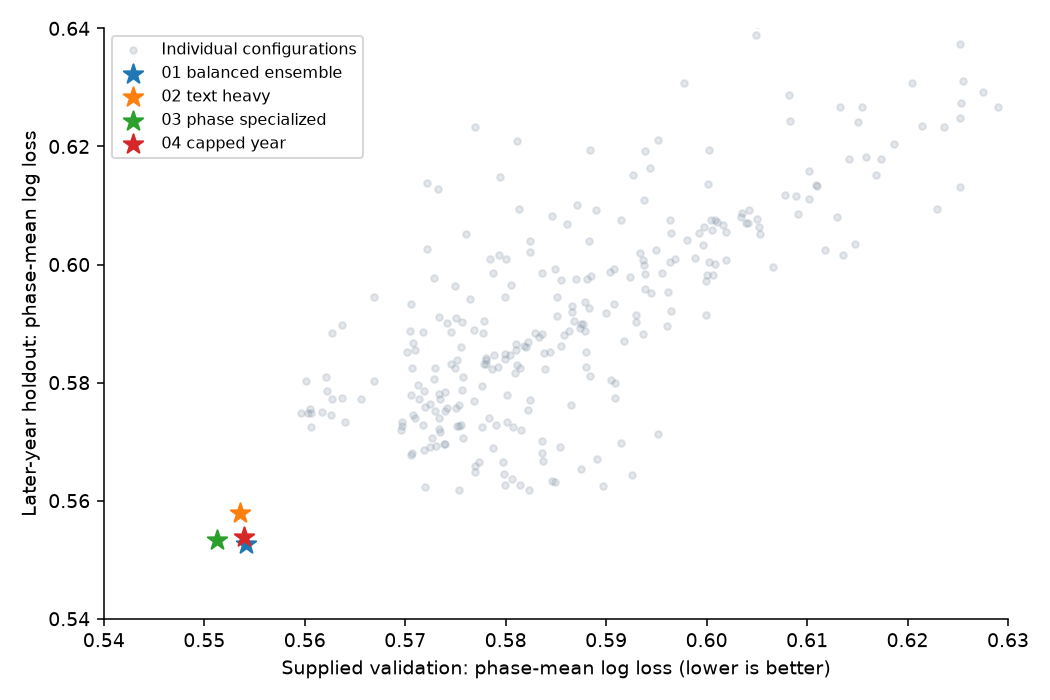

In [14]:
components = pd.read_csv(OUT / "all_component_scores.csv")
ensemble_scores = pd.read_csv(OUT / "ensemble_scores.csv")
print(f"{len(components)} matching component configurations; {len(ensemble_scores)} fixed ensemble configurations")
display(components[["name", "validation_phase_mean_logloss", "temporal_phase_mean_logloss", "joint_logloss"]].head(15))
display(ensemble_scores[["name", "validation_phase_mean_logloss", "temporal_phase_mean_logloss", "joint_logloss"]].head(12))
display(Image(filename=str(OUT / "figures/model_comparison.png")))


## Four manual Kaggle submissions

03 was selected first because it had the lowest local joint loss, but scored **0.59562**. 02 improved to **0.58993**, still behind the **0.58688** reference. Less tree influence in Phases II/III improved this comparison, but the cause of the generalization gap remains uncertain. The original four CSVs are preserved. Their predictions use models fitted on the full training file, never the reduced temporal fit.


In [15]:
index = pd.read_csv(ROOT / "submissions/index.csv")
display(index[["submission", "validation_logloss", "temporal_logloss", "mean_test_probability", "kaggle_score"]])
manifest = json.loads((ROOT / "submissions/manifest.json").read_text())
display(manifest["ensembles"])
test_predictions = pd.DataFrame({row.submission[:2]:pd.read_csv(ROOT/"submissions"/row.submission).label
                                 for row in index.itertuples()})
display(pd.DataFrame([[np.mean(np.abs(test_predictions[a]-test_predictions[b]))
                      for b in test_predictions] for a in test_predictions],
                     index=test_predictions.columns, columns=test_predictions.columns).rename_axis("Mean absolute test-probability difference"))


,submission,validation_logloss,temporal_logloss,mean_test_probability,kaggle_score
0,01_balanced_ensemble.csv,0.554134,0.552578,0.613147,NaN
1,02_text_heavy.csv,0.553592,0.557829,0.618782,0.58993
2,03_phase_specialized.csv,0.551255,0.553285,0.614596,0.59562
3,04_capped_year.csv,0.553970,0.553867,0.633393,NaN


{'01_balanced_ensemble': {'recency_clinical_C0.5_half3': 0.125,
  'recency_criteria_C2_half6': 0.1875,
  'catboost_d8_n1000_none': 0.25,
  'catboost_d6_n1000_none': 0.25,
  'text_wordwide_C2': 0.1875},
 '02_text_heavy': {'recency_clinical_C0.5_half3': 0.1875,
  'recency_criteria_C2_half6': 0.28125,
  'catboost_d8_n1000_none': 0.125,
  'catboost_d6_n1000_none': 0.125,
  'text_wordwide_C2': 0.28125},
 '03_phase_specialized': {'recency_clinical_C0.5_half3': {'I': 0.1875,
   'II': 0.125,
   'III': 0.0625},
  'recency_criteria_C2_half6': {'I': 0.28125, 'II': 0.1875, 'III': 0.09375},
  'catboost_d8_n1000_none': {'I': 0.125, 'II': 0.25, 'III': 0.375},
  'catboost_d6_n1000_none': {'I': 0.125, 'II': 0.25, 'III': 0.375},
  'text_wordwide_C2': {'I': 0.28125, 'II': 0.1875, 'III': 0.09375}},
 '04_capped_year': {'lr_criteria_yearcap_C2_phase0': 0.5,
  'catboost_d6_n1000_none': 0.25,
  'catboost_d8_n1000_none': 0.25}}

,01,02,03,04
Mean absolute test-probability difference,,,,
01,0.000000,0.02549,0.016721,0.022054
02,0.025490,0.00000,0.023160,0.025870
03,0.016721,0.02316,0.000000,0.028203
04,0.022054,0.02587,0.028203,0.000000


## Prospective follow-ups after the leaderboard feedback

05 keeps Phase I exactly as in 02 and removes trees in Phases II/III. 06 keeps Phase I unchanged and uses 12.5% trees in II/III. Both reuse the original fitted components without refitting or new outcome labels. **These are now on hold after the Ani comparison.** Their selection used the reported leaderboard direction; the new fixed benchmark gives a more informative comparison. Use the separate benchmark notebook for current Ani-anchored candidates and their uncertainty.


In [16]:
display(pd.read_csv(ROOT / "submissions/followup_index.csv"))
display(pd.read_csv(OUT / "followup_phase_metrics.csv"))
display(json.loads((ROOT / "submissions/followup_manifest.json").read_text())["ensembles"])
display(json.loads((ROOT / "submissions/leaderboard_results.json").read_text()))


,submission,validation_logloss,temporal_logloss,mean_test_probability,sha256,kaggle_score
0,05_text_later_phases.csv,0.558605,0.564306,0.621629,3c8d498a6ed79e3e2267a18784cc9b424576da038b5329...,NaN
1,06_lighter_tree_blend.csv,0.555718,0.560705,0.620205,064f8ca0935d4a7c4721d39dcd66e0229e1267f5c6a63b...,NaN


,submission,phase,tree_fraction,validation_logloss,temporal_logloss
0,05_text_later_phases.csv,I,0.250,0.559912,0.602510
1,05_text_later_phases.csv,II,0.000,0.593009,0.603734
2,05_text_later_phases.csv,III,0.000,0.522894,0.486674
3,06_lighter_tree_blend.csv,I,0.250,0.559912,0.602510
4,06_lighter_tree_blend.csv,II,0.125,0.590322,0.598383
5,06_lighter_tree_blend.csv,III,0.125,0.516922,0.481223


{'05_text_later_phases': {'catboost_d8_n1000_none': {'I': 0.125,
   'II': 0.0,
   'III': 0.0},
  'catboost_d6_n1000_none': {'I': 0.125, 'II': 0.0, 'III': 0.0},
  'recency_clinical_C0.5_half3': {'I': 0.1875, 'II': 0.25, 'III': 0.25},
  'text_wordwide_C2': {'I': 0.28125, 'II': 0.375, 'III': 0.375},
  'recency_criteria_C2_half6': {'I': 0.28125, 'II': 0.375, 'III': 0.375}},
 '06_lighter_tree_blend': {'catboost_d8_n1000_none': {'I': 0.125,
   'II': 0.0625,
   'III': 0.0625},
  'catboost_d6_n1000_none': {'I': 0.125, 'II': 0.0625, 'III': 0.0625},
  'recency_clinical_C0.5_half3': {'I': 0.1875, 'II': 0.21875, 'III': 0.21875},
  'text_wordwide_C2': {'I': 0.28125, 'II': 0.328125, 'III': 0.328125},
  'recency_criteria_C2_half6': {'I': 0.28125,
   'II': 0.328125,
   'III': 0.328125}}}

{'metric': 'log_loss',
 'lower_is_better': True,
 'prior_reported_best': 0.59528,
 'reference': {'kaggle_score': 0.58688,
  'source': 'Ani origin/ani commit 1b8bd11c47428fb5453e53cdc275542b92a3b347; user-reported and commit-reported Kaggle score, exact submission reproduced locally.',
  'validation_phase_mean_logloss_rounded': 0.556,
  'source_commit': '1b8bd11c47428fb5453e53cdc275542b92a3b347',
  'submission_sha256': '17caa6b02af919c8ba6358d680075208ba8d4f1d11c20d5b6d06e8f6d494b3c2'},
 'submissions': {'03_phase_specialized.csv': {'sha256': '52503212b3b46f347ad5c24c3a185a59843b865cf89d6369d0745c871342d892',
   'kaggle_score': 0.59562,
   'source': 'User-reported Kaggle result'},
  '02_text_heavy.csv': {'sha256': '46236538b620c456a95ebc2528e1498d9c4a9bd360f967bfe700604b681c41ec',
   'kaggle_score': 0.58993,
   'source': 'User-reported Kaggle result'}}}

## Per-phase performance

Success (`label=1`) is the positive class. F1 uses threshold 0.5. ROC-AUC and PR-AUC use success probabilities; PR-AUC is average precision. Compare all four candidates with the baseline, including trade-offs when log loss improves without an F1 improvement.


,model,phase,n,log_loss,f1,roc_auc,pr_auc
0,baseline,I,149,0.556186,0.765027,0.783456,0.834897
1,baseline,II,501,0.599672,0.656716,0.740086,0.717348
2,baseline,III,363,0.529385,0.833021,0.774187,0.862434
3,01_balanced_ensemble,I,149,0.567490,0.793103,0.779963,0.816854
4,01_balanced_ensemble,II,501,0.588929,0.668094,0.750608,0.733509
5,01_balanced_ensemble,III,363,0.505983,0.826415,0.802744,0.888202
6,02_text_heavy,I,149,0.559912,0.775281,0.789522,0.831860
7,02_text_heavy,II,501,0.588748,0.666667,0.751823,0.733693
8,02_text_heavy,III,363,0.512116,0.833333,0.798103,0.883937
9,03_phase_specialized,I,149,0.559912,0.775281,0.789522,0.831860


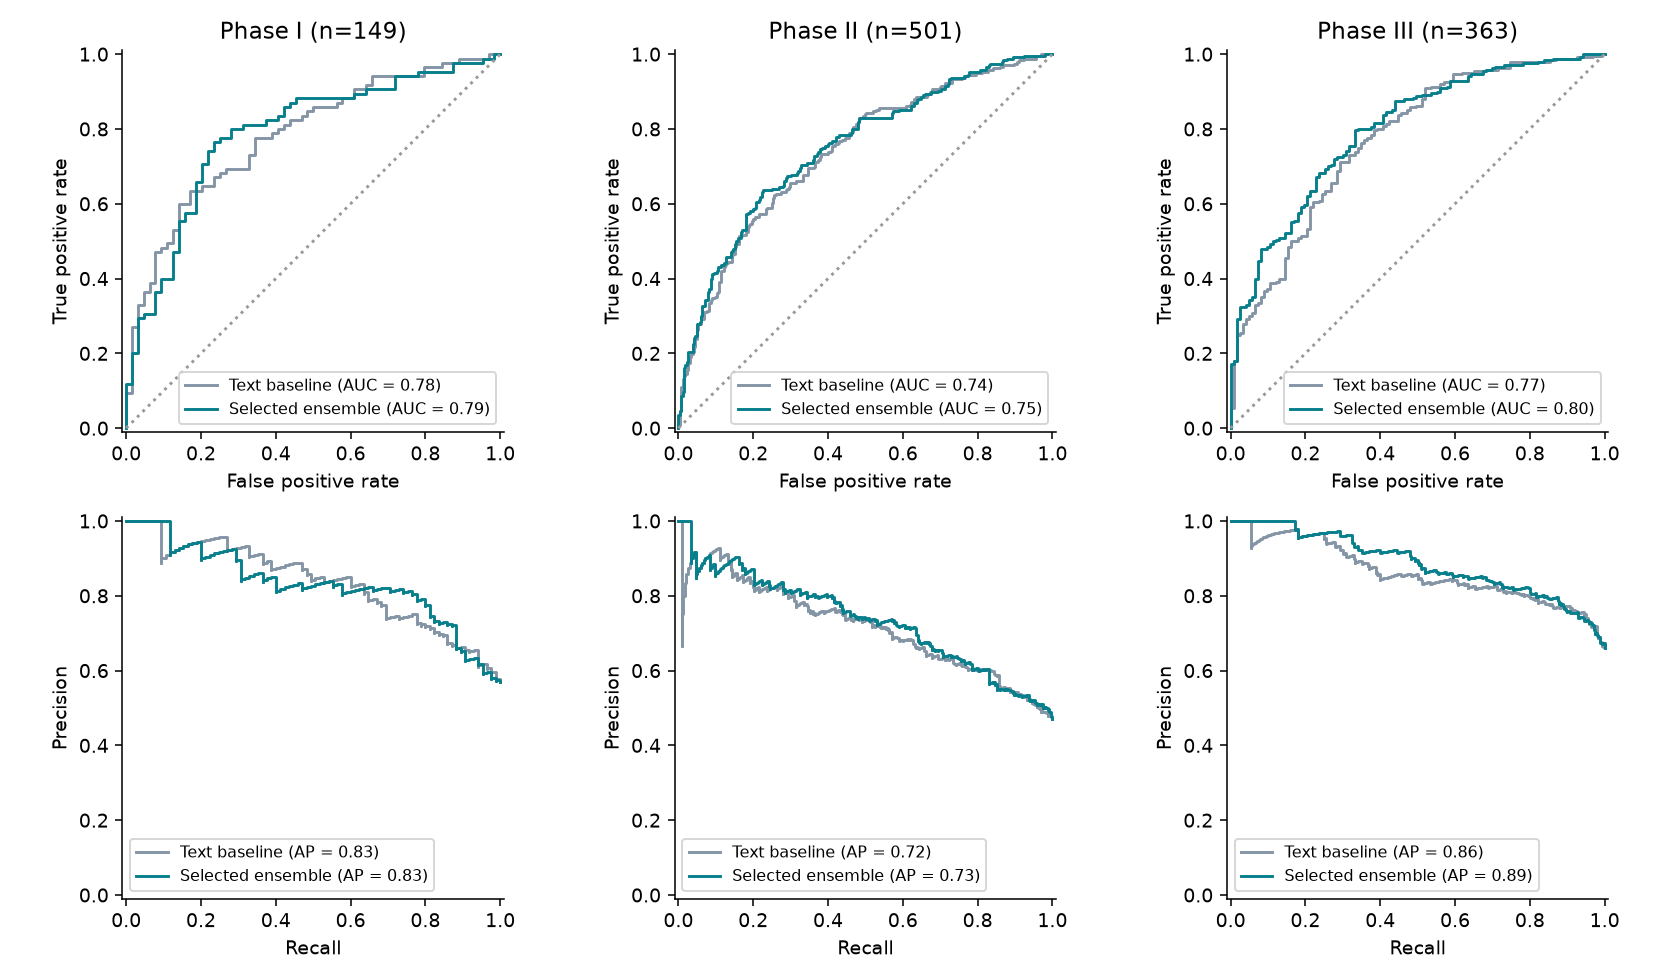

In [17]:
phase_metrics = pd.read_csv(OUT / "phase_metrics.csv")
display(phase_metrics)
display(Image(filename=str(OUT / "figures/phase_roc_pr.png")))


## Error analysis using Part One reasons

For unsuccessful validation rows, join `trial_id` to Part One `ID`. Use true visible train/validation reason labels when available; otherwise use the frozen original 157-label DBSCAN/logistic model (0.5 cutoff and argmax fallback). Trials absent from Part One form a separate no-recorded-stopping-reason group. Reasons can overlap. Count each trial once within each phase.

The baseline predicts success for 8 of 9 Phase III efficacy-tagged failures, suggesting that eligibility-only text misses important failure mechanisms. All nine tags are predicted, making this a small, uncertain subgroup. Clinical context, phase effects and nonlinear models are tested to broaden the predictor, while the tables below show their actual improvements and regressions. No reason label, embedding, or Part One membership is an outcome-model input.


,trials
Part One label source,
predicted_train,1014
predicted_test,312
true_train,157
true_val,78


{'path': 'part1/experiments/additional_methods/classifier_models/dbscan_m5_q25__logistic_C1000.joblib',
 'sha256': '522ae60a545a600b9f993ce4fac66d55e37c8ae8c4d7ba1dbe7dfa72f82598a3',
 'policy': 'Visible Part 1 train/val labels when available; otherwise frozen DBSCAN/logistic Part 1 model, cutoff 0.5, argmax fallback.',
 'usage': 'Error analysis only; none of these columns or embeddings is an outcome predictor.'}

,phase,reason,n,false_success_baseline,false_success_improved,false_success_rate_baseline,false_success_rate_improved,true_reason_rows_baseline,predicted_reason_rows_baseline
0,I,Safety,9,5,4,0.555556,0.444444,1,8
1,I,Funding,4,2,2,0.500000,0.500000,1,3
2,I,Efficacy,2,1,1,0.500000,0.500000,0,2
3,I,Recruitment,22,8,6,0.363636,0.272727,2,20
4,I,Other,5,4,4,0.800000,0.800000,0,5
5,I,No recorded stopping reason,28,12,11,0.428571,0.392857,0,0
6,II,Safety,15,6,6,0.400000,0.400000,1,14
7,II,Funding,4,0,1,0.000000,0.250000,1,3
8,II,Efficacy,10,3,3,0.300000,0.300000,0,10
9,II,Recruitment,87,17,14,0.195402,0.160920,12,75


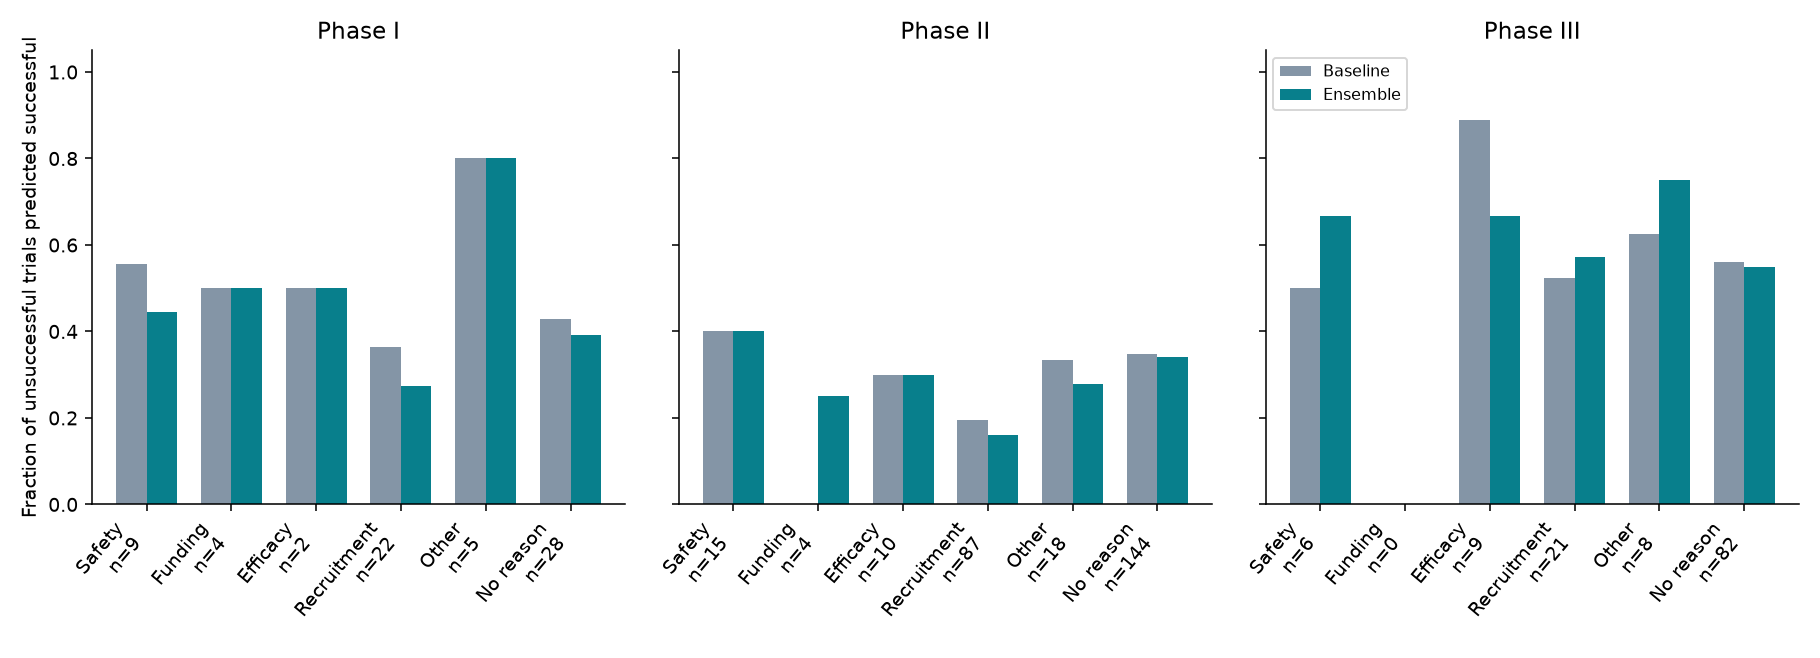

In [18]:
reasons = pd.read_csv(OUT / "reason_labels_for_analysis.csv")
display(reasons.reason_source.value_counts().rename_axis("Part One label source").to_frame("trials"))
display(json.loads((OUT / "reason_model_provenance.json").read_text()))
comparison = pd.read_csv(OUT / "reason_error_comparison.csv")
display(comparison[["phase", "reason", "n", "false_success_baseline", "false_success_improved",
                    "false_success_rate_baseline", "false_success_rate_improved",
                    "true_reason_rows_baseline", "predicted_reason_rows_baseline"]])
display(Image(filename=str(OUT / "figures/reason_errors.png")))


Funding has no unsuccessful Phase III examples in this validation set, so its rate is undefined. Small group sizes and uncertainty in predicted reason labels limit conclusions about differences between categories. Wilson intervals and the complete tables for every candidate are saved in CSV files. The paired trial-level bootstrap below is descriptive because the same validation set was used for selection.


In [19]:
display(pd.read_csv(OUT / "paired_validation_bootstrap.csv"))
display(pd.read_csv(OUT / "03_phase_specialized_reason_errors.csv"))


,model,delta_mean,delta_lower,delta_upper,fraction_lower_loss
0,01_balanced_ensemble,-0.007663,-0.020960,0.005984,0.8580
1,02_text_heavy,-0.008202,-0.017061,0.000524,0.9655
2,03_phase_specialized,-0.010526,-0.023718,0.002145,0.9485
3,04_capped_year,-0.007813,-0.019951,0.004309,0.8940


,phase,reason,n,false_success,false_success_rate,wilson_lower,wilson_upper,true_reason_rows,predicted_reason_rows
0,I,Safety,9,4,0.444444,0.188775,0.733353,1,8
1,I,Funding,4,2,0.500000,0.150036,0.849964,1,3
2,I,Efficacy,2,1,0.500000,0.094529,0.905471,0,2
3,I,Recruitment,22,6,0.272727,0.131506,0.481521,2,20
4,I,Other,5,4,0.800000,0.375528,0.963777,0,5
5,I,No recorded stopping reason,28,11,0.392857,0.235655,0.575913,0,0
6,II,Safety,15,6,0.400000,0.198242,0.642536,1,14
7,II,Funding,4,1,0.250000,0.045586,0.699364,1,3
8,II,Efficacy,10,3,0.300000,0.107789,0.603227,0,10
9,II,Recruitment,87,14,0.160920,0.098346,0.252172,12,75


## Verification and saved artifacts

Independent linear refits and saved tree-model reloads must reproduce the stored validation and test probabilities. All CSVs have exactly 1,500 unique IDs in sample-submission order, columns `ID,label`, and finite probabilities strictly between zero and one. `index.csv` is bookkeeping and should not be submitted.

The complete fitted bundle is `experiments/model_search/submission_models.joblib`. Reload inference with `python submission_models.py --input outcome_test.csv --output replayed_predictions`. Library versions are pinned in `requirements.txt`. No Kaggle upload is performed here.


In [20]:
checks = pd.read_csv(OUT / "model_replay_verification.csv")
assert checks.max_probability_difference.max() < 1e-8
display(checks)
sample = pd.read_csv(ROOT / "part2_sample_submission.csv")
all_files = pd.concat([index, pd.read_csv(ROOT / "submissions/followup_index.csv")], ignore_index=True)
for row in all_files.itertuples():
    result = pd.read_csv(ROOT / "submissions" / row.submission)
    assert result.columns.tolist() == ["ID", "label"]
    assert len(result) == 1500 and result.ID.nunique() == 1500
    assert result.ID.equals(sample.ID)
    assert np.isfinite(result.label).all() and result.label.between(0, 1, inclusive="neither").all()
print(f"All {len(all_files)} submissions pass the format, ID, and probability checks.")
display(json.loads((OUT / "versions.json").read_text()))


,component,split,max_probability_difference
0,catboost_d6_n1000_none,validation,0.0
1,catboost_d6_n1000_none,test,0.0
2,catboost_d8_n1000_none,validation,0.0
3,catboost_d8_n1000_none,test,0.0
4,lr_criteria_yearcap_C2_phase0,validation,0.0
5,lr_criteria_yearcap_C2_phase0,test,0.0
6,recency_clinical_C0.5_half3,validation,0.0
7,recency_clinical_C0.5_half3,test,0.0
8,recency_criteria_C2_half6,validation,0.0
9,recency_criteria_C2_half6,test,0.0


All 6 submissions pass the format, ID, and probability checks.


{'numpy': '2.5.2',
 'pandas': '3.0.5',
 'scipy': '1.18.1',
 'scikit-learn': '1.9.0',
 'catboost': '1.2.10',
 'lightgbm': '4.7.0',
 'rdkit': '2026.9.1',
 'joblib': '1.6.0',
 'matplotlib': '3.11.1',
 'nbformat': '5.11.1',
 'nbclient': '0.11.0',
 'ipykernel': '7.3.0'}